# ARIMA_MODEL and SARIMAX model

### Step 1

In [2]:
# Cell 0 - imports and helper functions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.max_open_warning": 0})


In [3]:
# Cell 1 - load data and inspect
df = pd.read_csv('Walmart.csv')
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values(['Store','Date']).reset_index(drop=True)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique stores:", df['Store'].nunique())
print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())

# Show head
display(df.head())


Shape: (6435, 8)
Columns: ['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
Unique stores: 45
Date range: 2010-02-05 to 2012-10-26


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


Correlation and pairwise plots between Weekly_Sales and other features


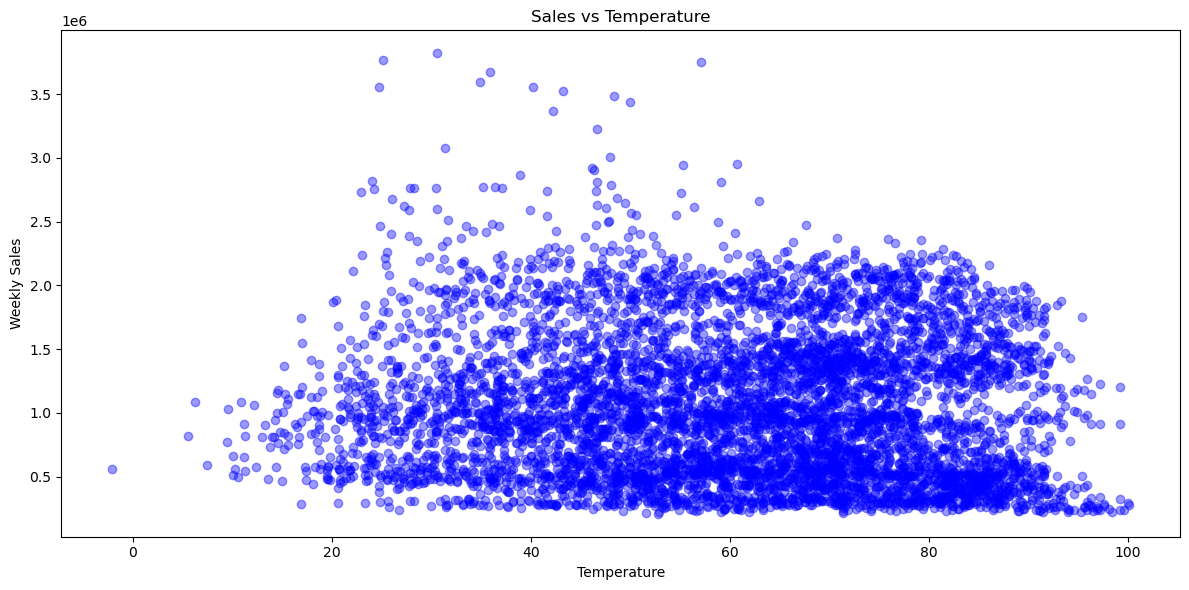

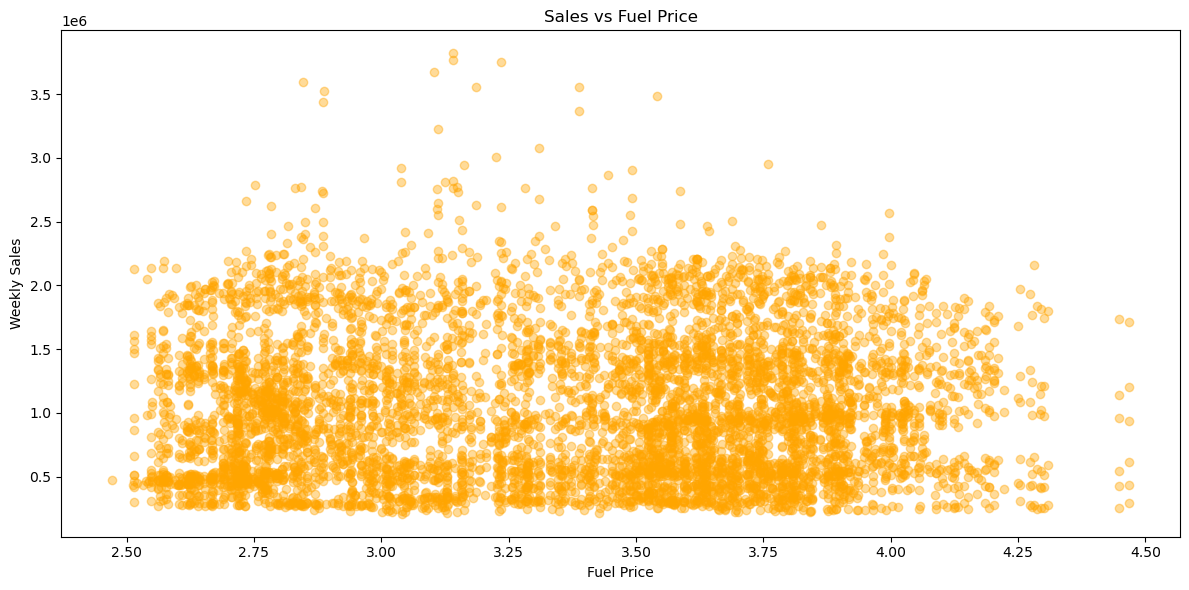

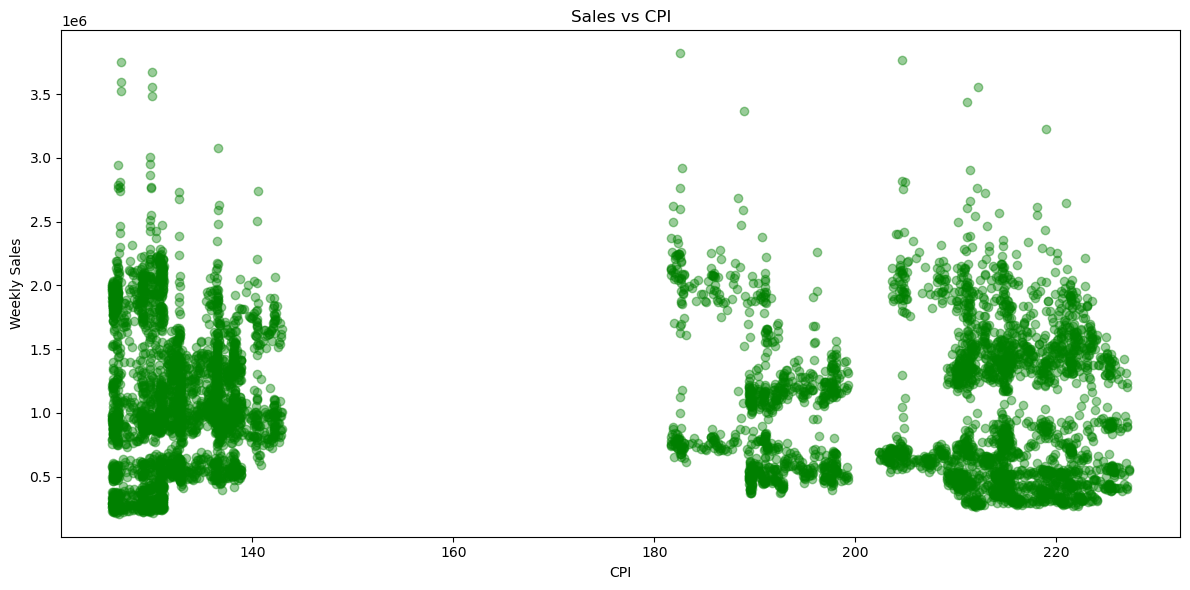

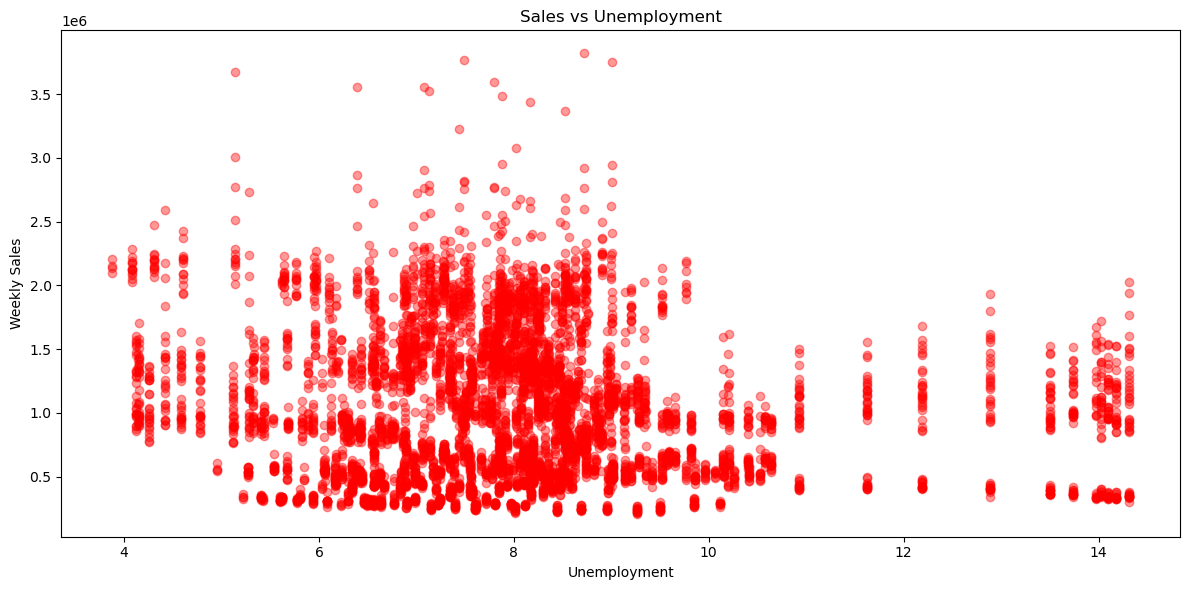

In [4]:
# Cell X - Exploratory analysis: Sales vs other variables

import seaborn as sns
import matplotlib.pyplot as plt

# Compute average weekly sales per store (to smooth a bit)
# or use full data directly depending on what you want
print("Correlation and pairwise plots between Weekly_Sales and other features")

num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# 1️⃣ Sales vs. Temperature
plt.figure(figsize=(12,6))
plt.scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.4, color='blue')
plt.title("Sales vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 2️⃣ Sales vs. Fuel Price
plt.figure(figsize=(12,6))
plt.scatter(df['Fuel_Price'], df['Weekly_Sales'], alpha=0.4, color='orange')
plt.title("Sales vs Fuel Price")
plt.xlabel("Fuel Price")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 3️⃣ Sales vs. CPI
plt.figure(figsize=(12,6))
plt.scatter(df['CPI'], df['Weekly_Sales'], alpha=0.4, color='green')
plt.title("Sales vs CPI")
plt.xlabel("CPI")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 4️⃣ Sales vs. Unemployment
plt.figure(figsize=(12,6))
plt.scatter(df['Unemployment'], df['Weekly_Sales'], alpha=0.4, color='red')
plt.title("Sales vs Unemployment")
plt.xlabel("Unemployment")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()


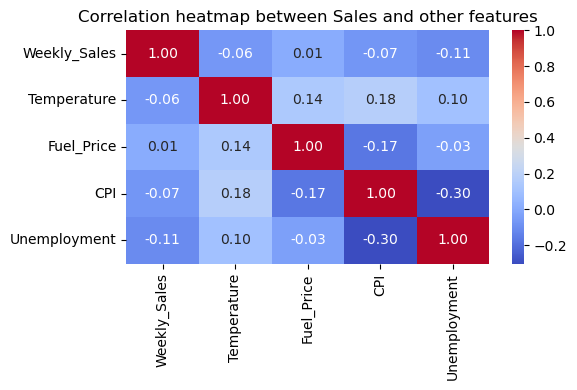

Weekly_Sales    1.000000
Fuel_Price      0.009464
Temperature    -0.063810
CPI            -0.072634
Unemployment   -0.106176
Name: Weekly_Sales, dtype: float64


In [5]:
# Cell Y - Correlation matrix heatmap
corr = df[num_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation heatmap between Sales and other features")
plt.tight_layout()
plt.show()

print(corr['Weekly_Sales'].sort_values(ascending=False))


In [6]:
# Cell Z - Select top correlated features for SARIMAX
corr = df[['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']].corr()
top_features = corr['Weekly_Sales'].drop('Weekly_Sales').abs().sort_values(ascending=False).head(2).index.tolist()

print(f"Top correlated features with Weekly_Sales: {top_features}")

# We’ll use these as exogenous variables


Top correlated features with Weekly_Sales: ['Unemployment', 'CPI']


Example store: 2
Data points: 143


Date
2010-02-05    2136989.46
2010-02-12    2137809.50
2010-02-19    2124451.54
2010-02-26    1865097.27
2010-03-05    1991013.13
Name: Weekly_Sales, dtype: float64

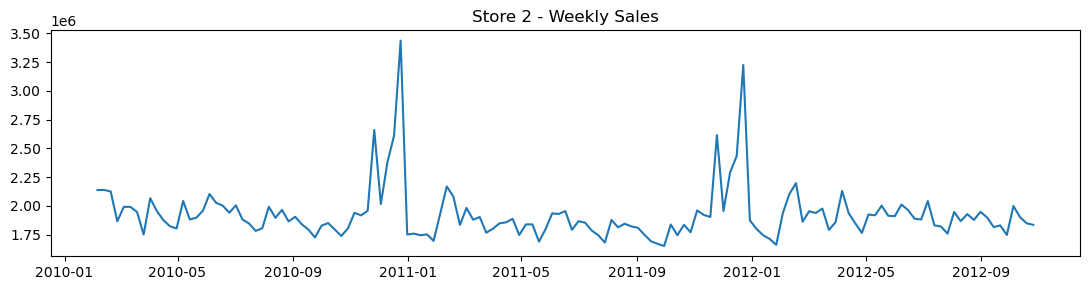

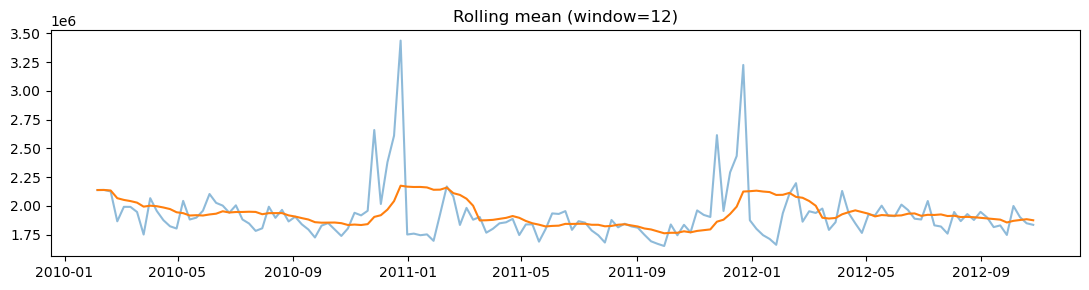

Total: 143, Train: 100, Val: 21, Test: 22


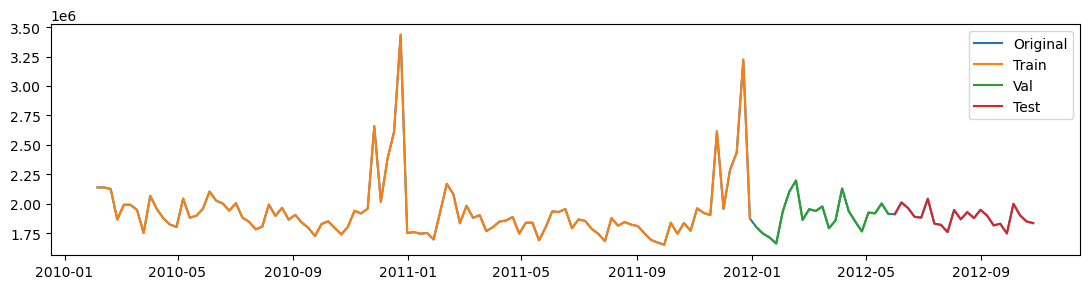

In [7]:
# Cell 2 - pick an example store and split to train/val/test (time-based)
example_store = int(df['Store'].unique()[1])   # choose second store as example
print("Example store:", example_store)

store_df = df[df['Store'] == example_store].copy().set_index('Date').sort_index()
series = store_df['Weekly_Sales'].sort_index().dropna()

print("Data points:", len(series))
display(series.head())

# Plot raw series + rolling mean (quick trend check)
plt.figure(figsize=(11,3))
plt.plot(series, label='Weekly_Sales')
plt.title(f"Store {example_store} - Weekly Sales")
plt.tight_layout(); plt.show()

rolling = series.rolling(window=12, min_periods=1).mean()
plt.figure(figsize=(11,3))
plt.plot(series, alpha=0.5)
plt.plot(rolling)
plt.title("Rolling mean (window=12)")
plt.tight_layout(); plt.show()

# Time-based split
n = len(series)
n_train = int(0.7 * n)
n_val   = int(0.15 * n)
n_test  = n - n_train - n_val

train = series.iloc[:n_train]
val   = series.iloc[n_train:n_train + n_val]
test  = series.iloc[n_train + n_val:]

print(f"Total: {n}, Train: {len(train)}, Val: {len(val)}, Test: {len(test)}")
plt.figure(figsize=(11,3))
plt.plot(series, label='Original')
plt.plot(train, label='Train')
plt.plot(val, label='Val')
plt.plot(test, label='Test')
plt.legend()
plt.tight_layout(); plt.show()


We notice seasonality as there are spikes around Christmas and new year eve in every 52 weeks. so there is yearly seasonality, though there is no strong upward or downward trend. 

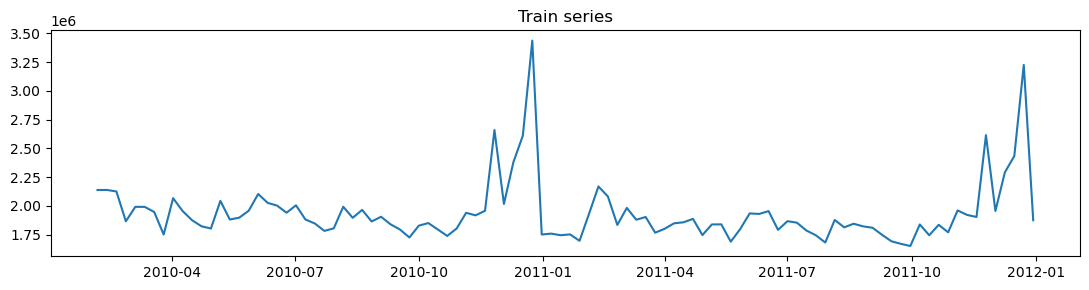

<Figure size 1100x300 with 0 Axes>

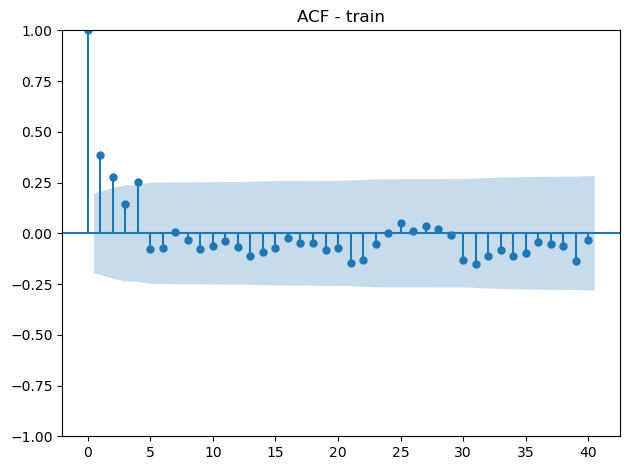

<Figure size 1100x300 with 0 Axes>

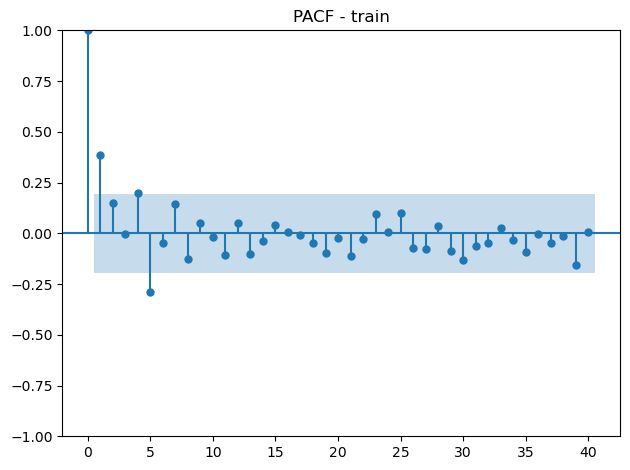

---- ADF test: train ----
ADF Stat: -3.5393  p-value: 0.0070  lags: 4  obs:95
  Crit 1%: -3.5011
  Crit 5%: -2.8925
  Crit 10%: -2.5833
Stationary? Yes (p<=0.05)
-------------------------------



In [8]:
# Cell 3 - Stationarity checks on train
def adf_test_print(s, label="Series"):
    print("---- ADF test:", label, "----")
    if len(s.dropna()) < 3:
        print("Series too short for ADF test.")
        return
    res = adfuller(s.dropna(), autolag='AIC')
    print("ADF Stat: %.4f  p-value: %.4f  lags: %d  obs:%d" % (res[0], res[1], res[2], res[3]))
    for k,v in res[4].items():
        print("  Crit %s: %.4f" % (k,v))
    print("Stationary?" , "Yes (p<=0.05)" if res[1] <= 0.05 else "No (p>0.05)")
    print("-------------------------------\n")

# Plot series, ACF, PACF and run ADF
lags_to_use = min(40, max(10, len(train)//2))
plt.figure(figsize=(11,3)); plt.plot(train); plt.title("Train series"); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_acf(train.dropna(), lags=lags_to_use, title='ACF - train'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(train.dropna(), lags=lags_to_use, title='PACF - train'); plt.tight_layout(); plt.show()
adf_test_print(train, label='train')


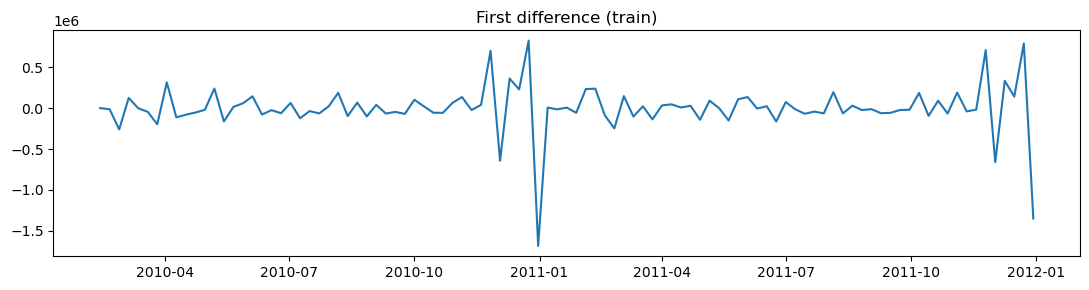

<Figure size 1100x300 with 0 Axes>

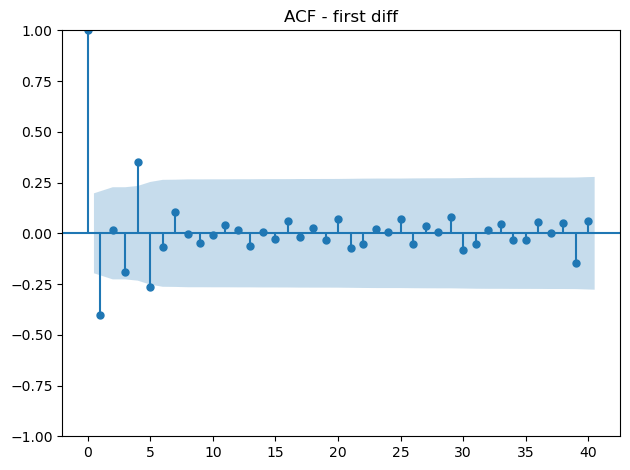

<Figure size 1100x300 with 0 Axes>

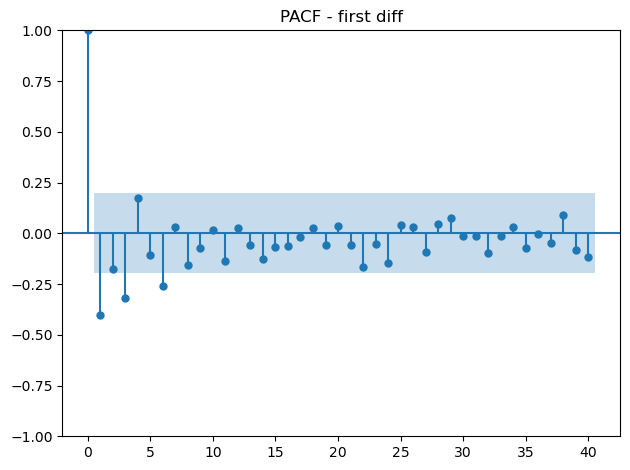

---- ADF test: first-diff(train) ----
ADF Stat: -5.9456  p-value: 0.0000  lags: 5  obs:93
  Crit 1%: -3.5027
  Crit 5%: -2.8932
  Crit 10%: -2.5836
Stationary? Yes (p<=0.05)
-------------------------------



In [9]:
# Cell 4 - differencing and check again
diff1 = train.diff().dropna()
plt.figure(figsize=(11,3)); plt.plot(diff1); plt.title("First difference (train)"); plt.tight_layout(); plt.show()

lags_to_use = min(40, max(10, len(diff1)//2))
plt.figure(figsize=(11,3)); plot_acf(diff1, lags=lags_to_use, title='ACF - first diff'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(diff1, lags=lags_to_use, title='PACF - first diff'); plt.tight_layout(); plt.show()
adf_test_print(diff1, label='first-diff(train)')

# If you suspect yearly seasonality (weekly data -> period=52), check seasonal diff
if len(train) > 52*2:
    sdiff = train.diff(52).dropna()
    plt.figure(figsize=(11,3)); plt.plot(sdiff); plt.title("Seasonal diff (lag=52)"); plt.tight_layout(); plt.show()
    plt.figure(figsize=(11,3)); plot_acf(sdiff, lags=lags_to_use, title='ACF - seasonal diff'); plt.tight_layout(); plt.show()
    plt.figure(figsize=(11,3)); plot_pacf(sdiff, lags=lags_to_use, title='PACF - seasonal diff'); plt.tight_layout(); plt.show()
    adf_test_print(sdiff, label='seasonal-diff(train,52)')


In [10]:
# Cell 5 - guidance
print("Manual p/q guidance:")
print("- If PACF cuts off after lag k and ACF tails -> AR(p=k).")
print("- If ACF cuts off after lag k and PACF tails -> MA(q=k).")
print("- If both tail slowly -> increase d (difference).")
print("Use the ACF/PACF of the differenced series above to pick p and q.")
# Default example start:
p,d,q = 1,0,1
print("Demo starting point: ARIMA(%d,%d,%d)" % (p,d,q))


Manual p/q guidance:
- If PACF cuts off after lag k and ACF tails -> AR(p=k).
- If ACF cuts off after lag k and PACF tails -> MA(q=k).
- If both tail slowly -> increase d (difference).
Use the ACF/PACF of the differenced series above to pick p and q.
Demo starting point: ARIMA(1,0,1)


In [11]:
# Cell 6 - fit ARIMA
model = ARIMA(train, order=(p,d,q))
fitted = model.fit()
print(fitted.summary())


                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  100
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -1384.370
Date:                Sun, 05 Oct 2025   AIC                           2776.741
Time:                        17:07:43   BIC                           2787.161
Sample:                    02-05-2010   HQIC                          2780.958
                         - 12-30-2011                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.939e+06   8.02e+04     24.163      0.000    1.78e+06     2.1e+06
ar.L1          0.7266      0.177      4.112      0.000       0.380       1.073
ma.L1         -0.4083      0.225     -1.817      0.0

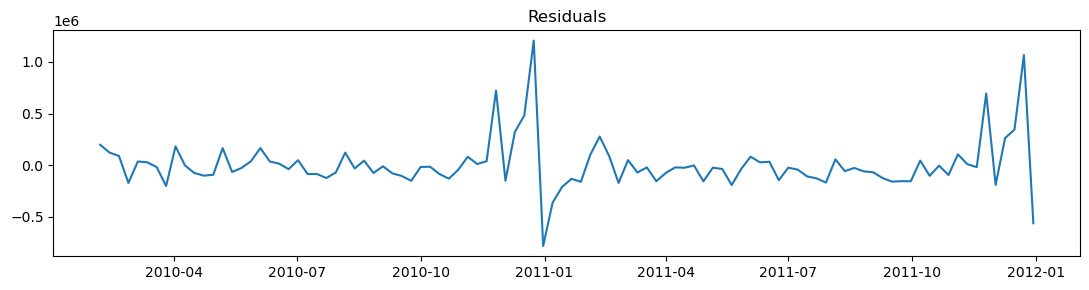

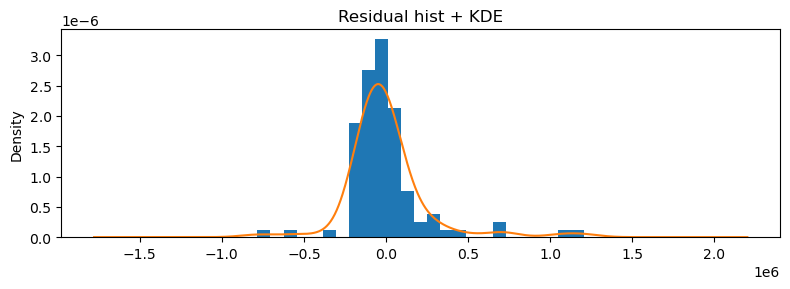

<Figure size 1100x300 with 0 Axes>

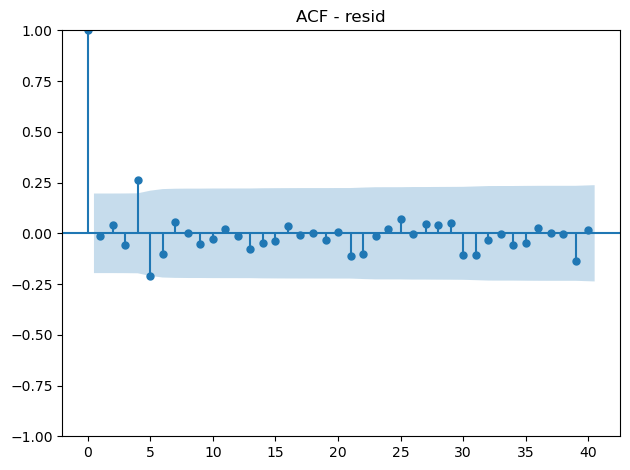

<Figure size 1100x300 with 0 Axes>

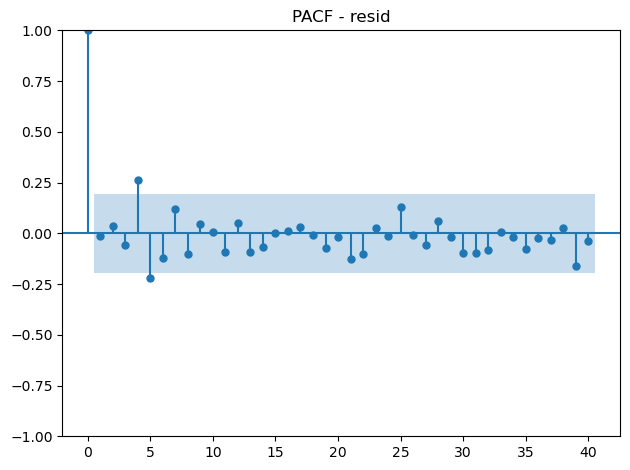

In [12]:
# Cell 7 - residuals diagnostics
resid = fitted.resid.dropna()
plt.figure(figsize=(11,3)); plt.plot(resid); plt.title("Residuals"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,3)); resid.plot(kind='hist', bins=25, density=True); resid.plot(kind='kde'); plt.title("Residual hist + KDE"); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_acf(resid, lags=min(40, len(resid)-1), title='ACF - resid'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11,3)); plot_pacf(resid, lags=min(40, len(resid)-1), title='PACF - resid'); plt.tight_layout(); plt.show()


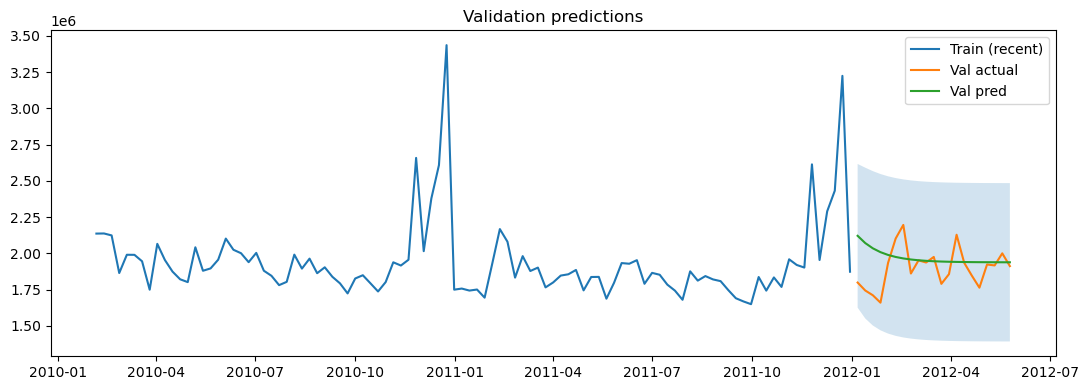

Validation MAE, MAPE, RMSE: 128483.73594873695 6.994156607455657 173248.61234961587


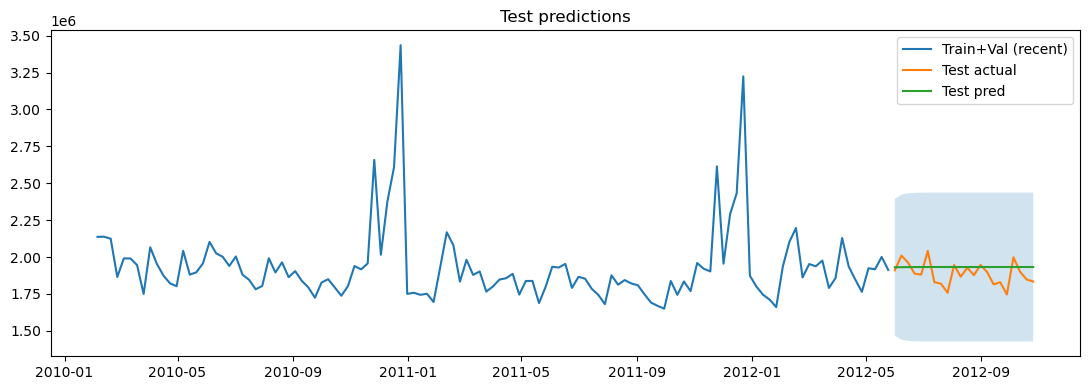

Test MAE, MAPE, RMSE: 72760.21480254011 3.9264029529666686 87424.73163784956


In [13]:
# Cell 8 - forecast & evaluate
def mae(y, yhat): return np.mean(np.abs(y - yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / np.where(y==0, np.nan, y))) * 100
def rmse(y, yhat): return np.sqrt(np.mean((y - yhat)**2))

# Predict on validation using fitted (forecast steps = len(val))
if len(val) > 0:
    fc_val = fitted.get_forecast(steps=len(val))
    val_pred = pd.Series(fc_val.predicted_mean, index=val.index)
    val_conf = fc_val.conf_int()
    val_conf.index = val.index
    # plot
    plt.figure(figsize=(11,4))
    plt.plot(train[-len(train):], label='Train (recent)')
    plt.plot(val, label='Val actual')
    plt.plot(val_pred, label='Val pred')
    plt.fill_between(val.index, val_conf.iloc[:,0].values, val_conf.iloc[:,1].values, alpha=0.2)
    plt.legend(); plt.title("Validation predictions"); plt.tight_layout(); plt.show()
    print("Validation MAE, MAPE, RMSE:", mae(val, val_pred), mape(val, val_pred), rmse(val, val_pred))

# Refit on train+val and forecast test
train_val = pd.concat([train, val]) if len(val) > 0 else train
model_tv = ARIMA(train_val, order=(p,d,q)).fit()
if len(test) > 0:
    fc_test = model_tv.get_forecast(steps=len(test))
    test_pred = pd.Series(fc_test.predicted_mean, index=test.index)
    test_conf = fc_test.conf_int()
    test_conf.index = test.index
    plt.figure(figsize=(11,4))
    plt.plot(train_val[-len(train_val):], label='Train+Val (recent)')
    plt.plot(test, label='Test actual')
    plt.plot(test_pred, label='Test pred')
    plt.fill_between(test.index, test_conf.iloc[:,0].values, test_conf.iloc[:,1].values, alpha=0.2)
    plt.legend(); plt.title("Test predictions"); plt.tight_layout(); plt.show()
    print("Test MAE, MAPE, RMSE:", mae(test, test_pred), mape(test, test_pred), rmse(test, test_pred))


SARIMAX Validation MAE: 280277.61
SARIMAX Validation RMSE: 312145.14


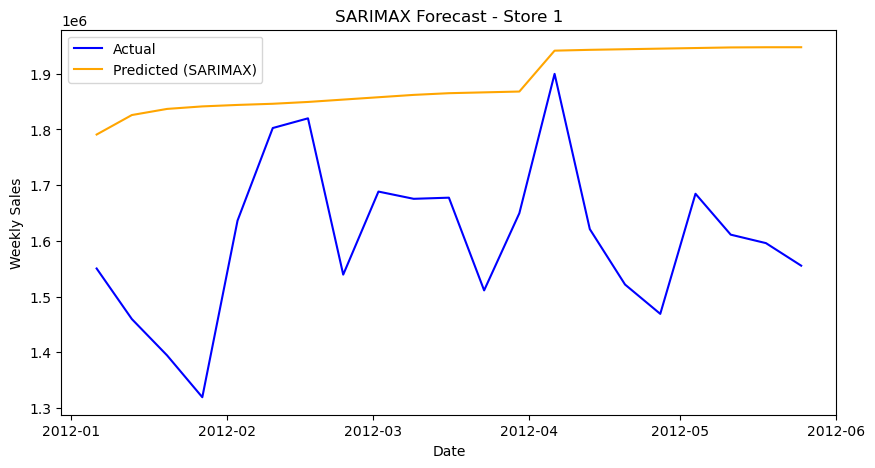

In [14]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Example: Using Store 1 for demonstration
store_id = 1
store_data = df[df['Store'] == store_id].copy()
store_data['Date'] = pd.to_datetime(store_data['Date'])
store_data = store_data.sort_values('Date')

# Define train/val/test split (70-15-15)
n = len(store_data)
train_end = int(0.7 * n)
val_end = int(0.85 * n)

train = store_data.iloc[:train_end]
val = store_data.iloc[train_end:val_end]
test = store_data.iloc[val_end:]

# Prepare exogenous variables
exog_cols = top_features
train_exog = train[exog_cols]
val_exog = val[exog_cols]
test_exog = test[exog_cols]

# Fit SARIMAX (same (p,d,q) as ARIMA)
sarimax_model = SARIMAX(train['Weekly_Sales'], exog=train_exog, order=(1,1,1))
sarimax_result = sarimax_model.fit(disp=False)

# Forecast using validation set
forecast = sarimax_result.predict(start=val.index[0], end=val.index[-1], exog=val_exog)

# Evaluate
mae = mean_absolute_error(val['Weekly_Sales'], forecast)
rmse = mean_squared_error(val['Weekly_Sales'], forecast, squared=False)

print(f"SARIMAX Validation MAE: {mae:.2f}")
print(f"SARIMAX Validation RMSE: {rmse:.2f}")

# Plot predicted vs actual
plt.figure(figsize=(10,5))
plt.plot(val['Date'], val['Weekly_Sales'], label='Actual', color='blue')
plt.plot(val['Date'], forecast, label='Predicted (SARIMAX)', color='orange')
plt.title(f"SARIMAX Forecast - Store {store_id}")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()


In [15]:
# Cell 9 - optional auto_arima using pmdarima
try:
    import pmdarima as pm
    auto = pm.auto_arima(train, seasonal=False, stepwise=True, suppress_warnings=True,
                         error_action='ignore', max_p=5, max_q=5, max_d=2)
    print("Auto ARIMA order:", auto.order)
    print(auto.summary())
except Exception as e:
    print("pmdarima not installed. Install with: pip install pmdarima")


pmdarima not installed. Install with: pip install pmdarima


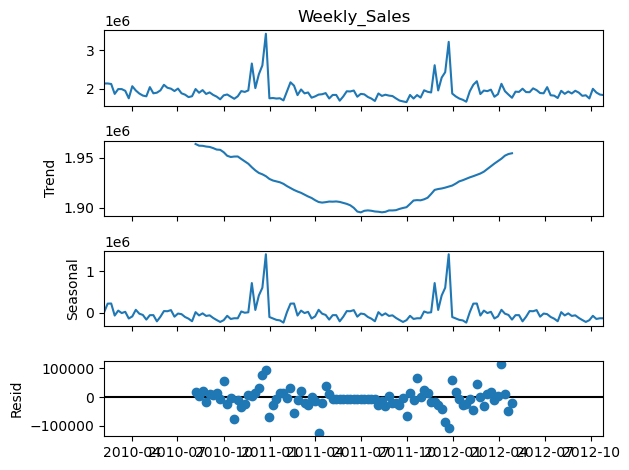

In [16]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(series, model='additive', period=52)  # 52 weeks in a year
result.plot()
plt.show()


Processing store 1/45 (Store ID: 1)...
  Store 1 -> MAE: 85429.43, RMSE: 98755.57


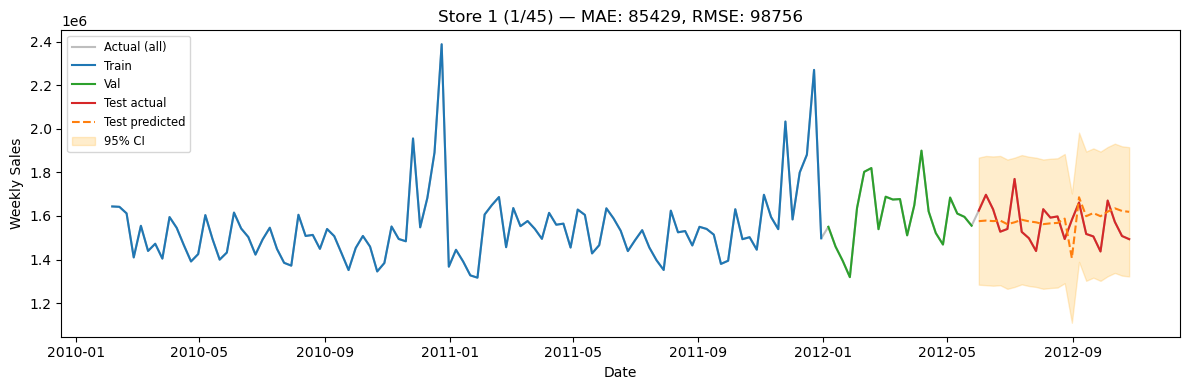

Processing store 2/45 (Store ID: 2)...
  Store 2 -> MAE: 78126.75, RMSE: 105555.85


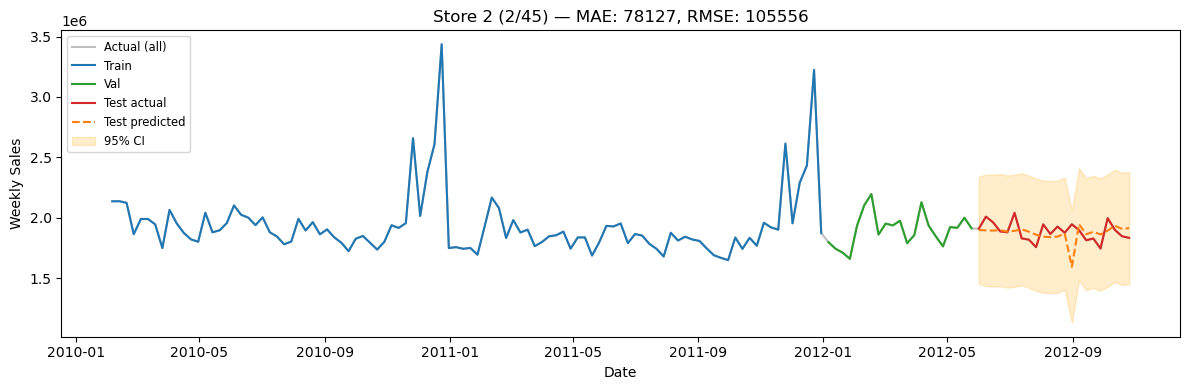

Processing store 3/45 (Store ID: 3)...
  Store 3 -> MAE: 19653.47, RMSE: 23548.29


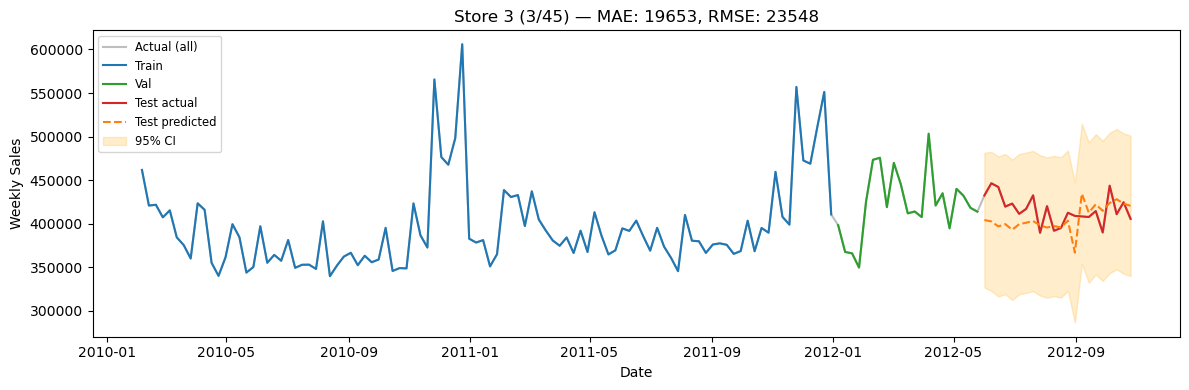

Processing store 4/45 (Store ID: 4)...
  Store 4 -> MAE: 87019.22, RMSE: 103371.62


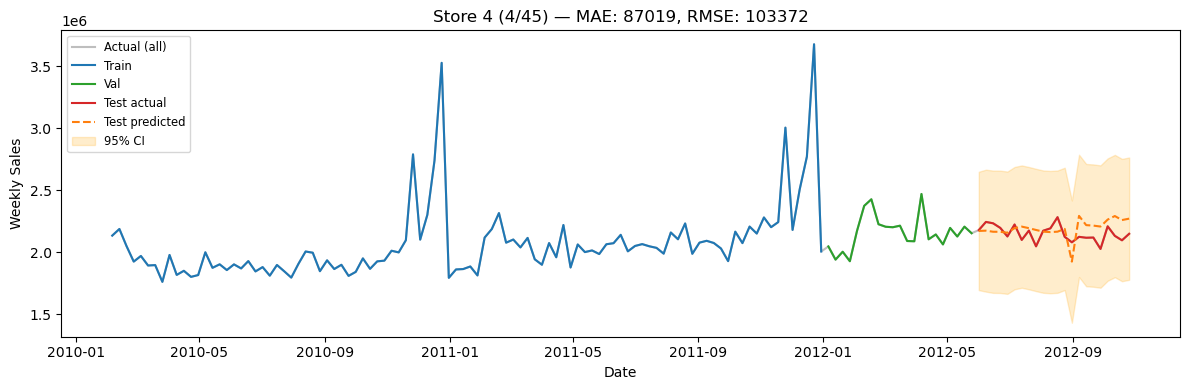

Processing store 5/45 (Store ID: 5)...
  Store 5 -> MAE: 19513.73, RMSE: 22637.59


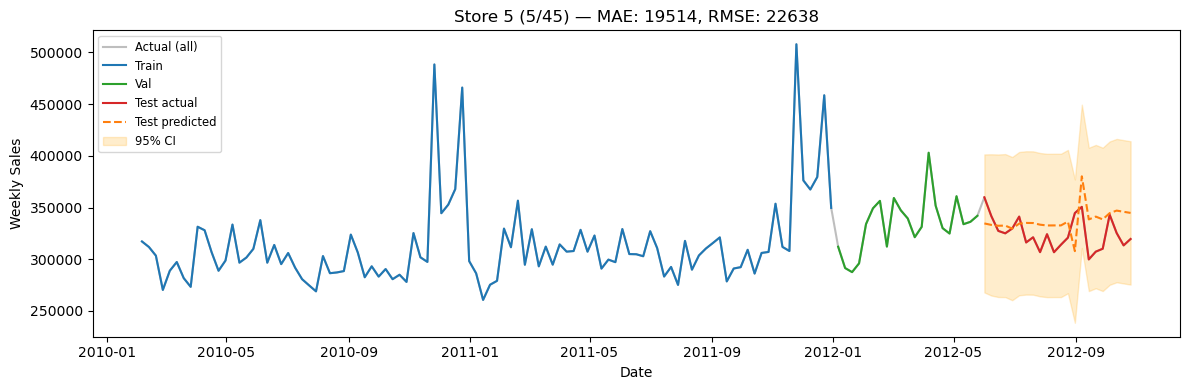

Processing store 6/45 (Store ID: 6)...
  Store 6 -> MAE: 96447.25, RMSE: 122557.43


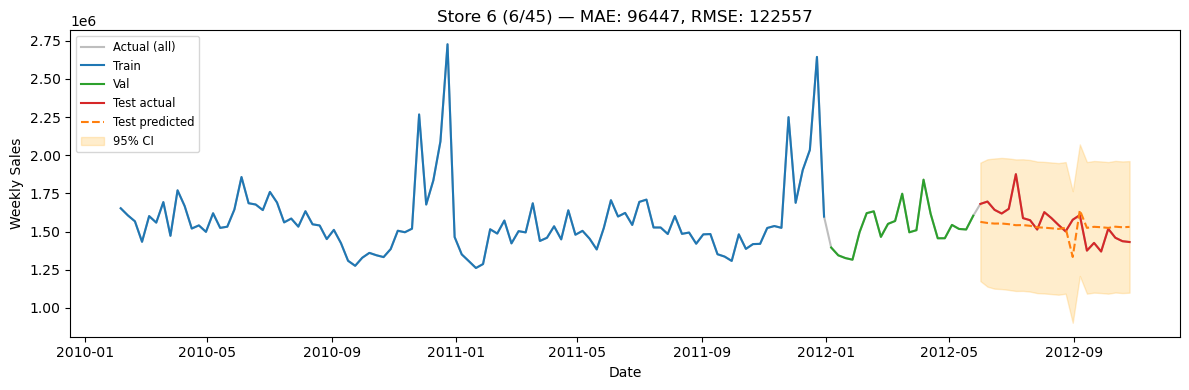

Processing store 7/45 (Store ID: 7)...
  Store 7 -> MAE: 95430.79, RMSE: 104173.45


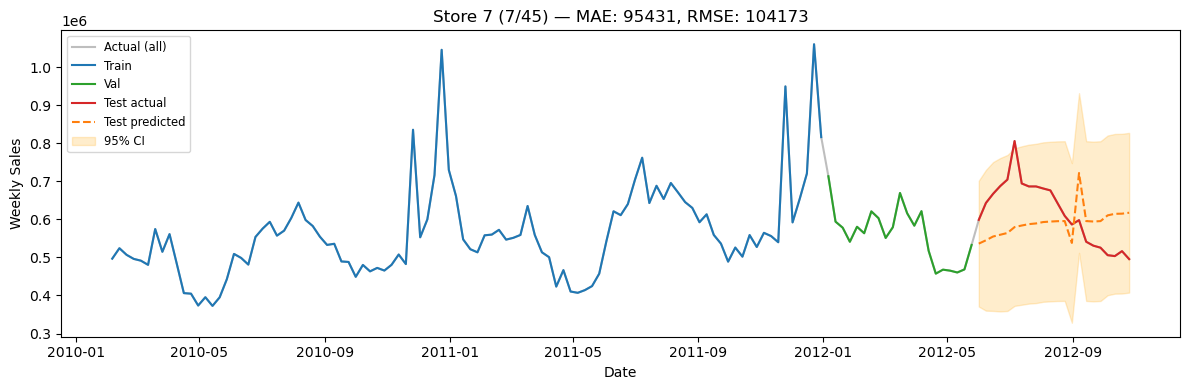

Processing store 8/45 (Store ID: 8)...
  Store 8 -> MAE: 51394.76, RMSE: 73039.27


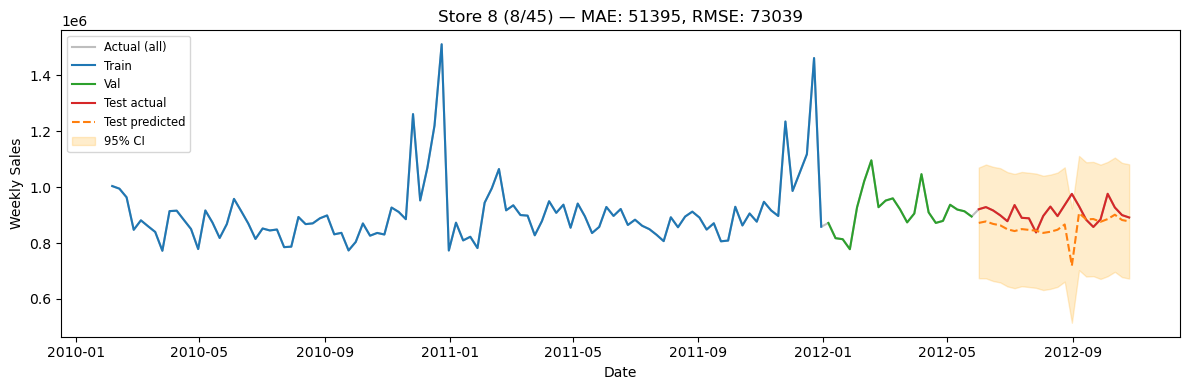

Processing store 9/45 (Store ID: 9)...
  Store 9 -> MAE: 30970.94, RMSE: 36066.52


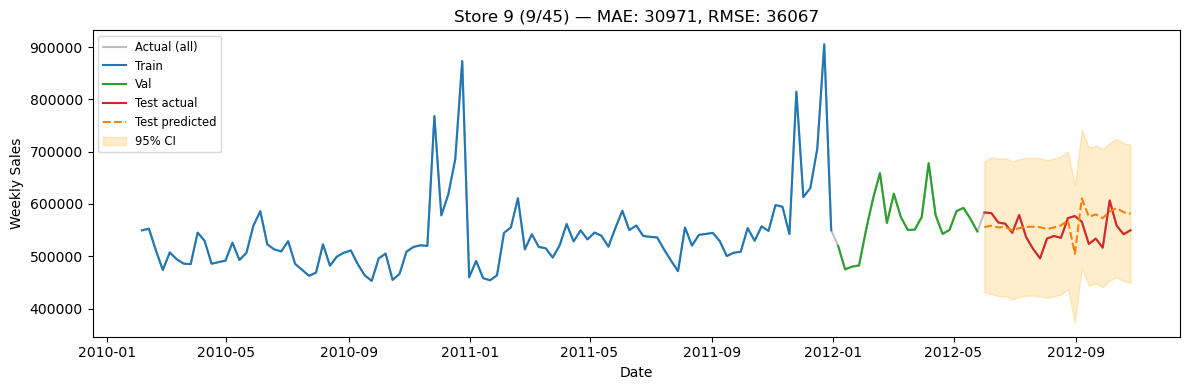

Processing store 10/45 (Store ID: 10)...
  Store 10 -> MAE: 92103.46, RMSE: 111767.55


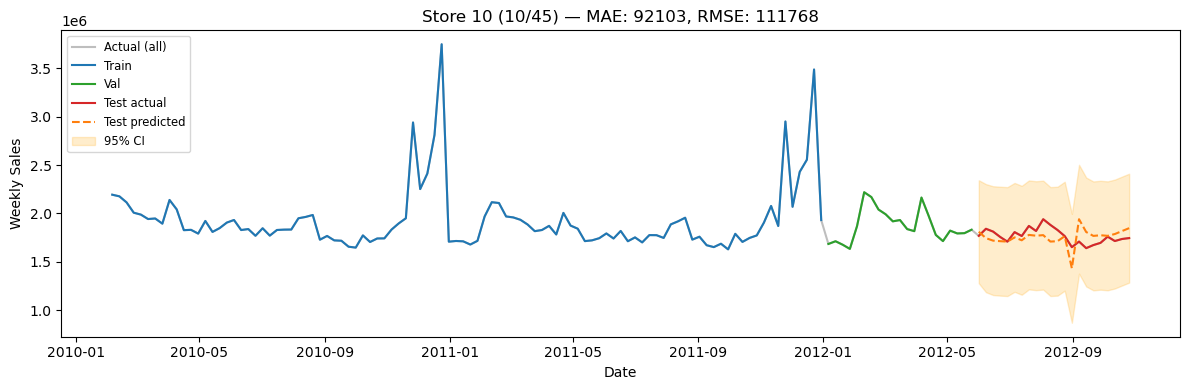

Processing store 11/45 (Store ID: 11)...
  Store 11 -> MAE: 81346.23, RMSE: 97045.77


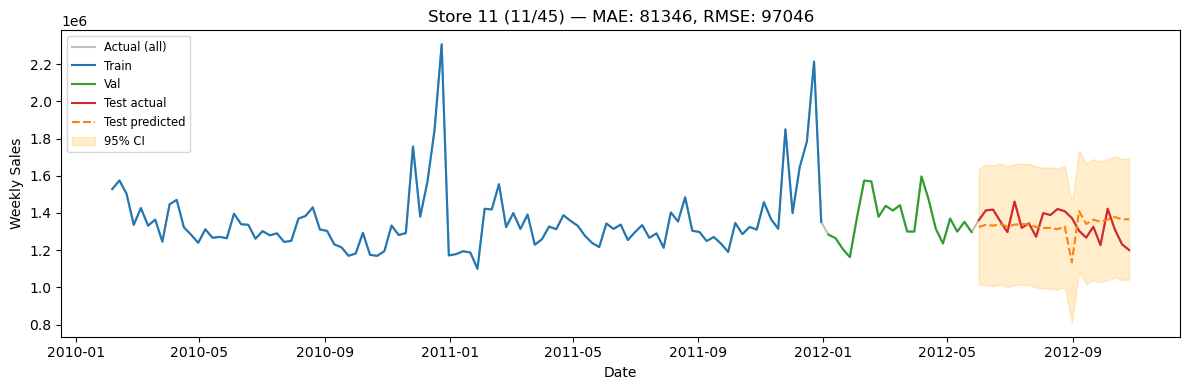

Processing store 12/45 (Store ID: 12)...
  Store 12 -> MAE: 67368.30, RMSE: 85900.30


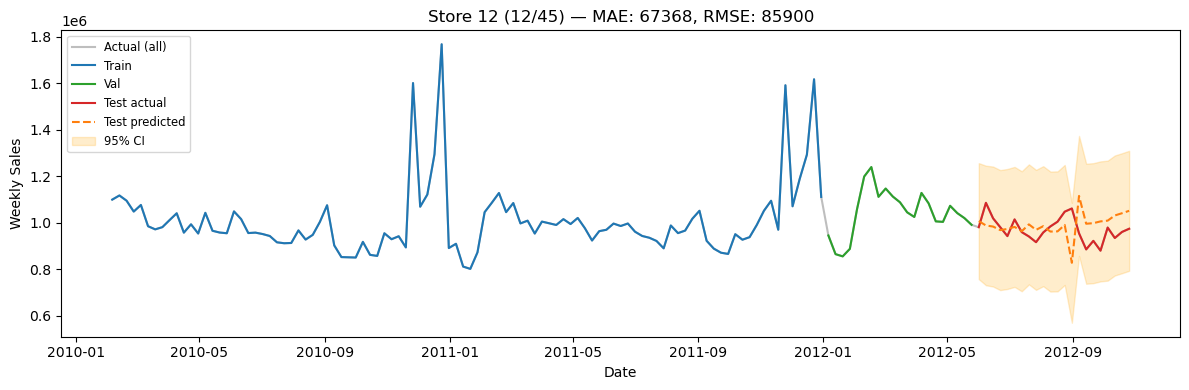

Processing store 13/45 (Store ID: 13)...
  Store 13 -> MAE: 86268.83, RMSE: 112164.16


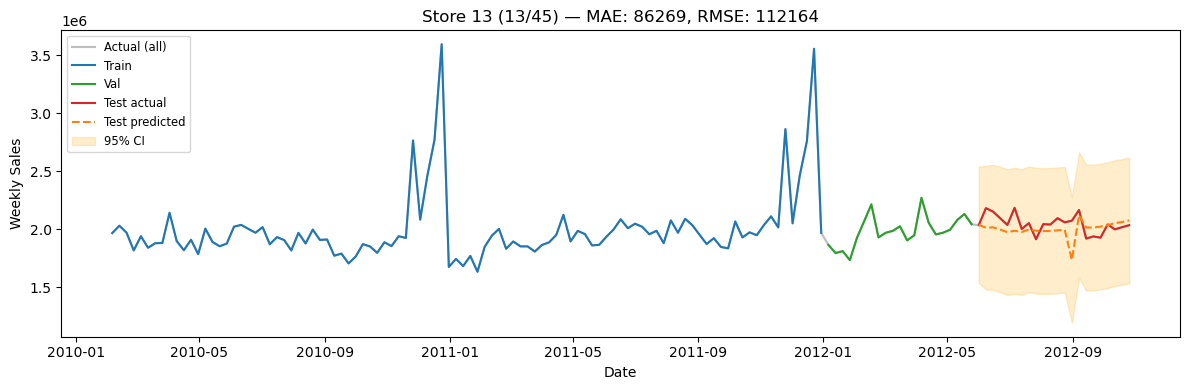

Processing store 14/45 (Store ID: 14)...
  Store 14 -> MAE: 334943.82, RMSE: 366578.90


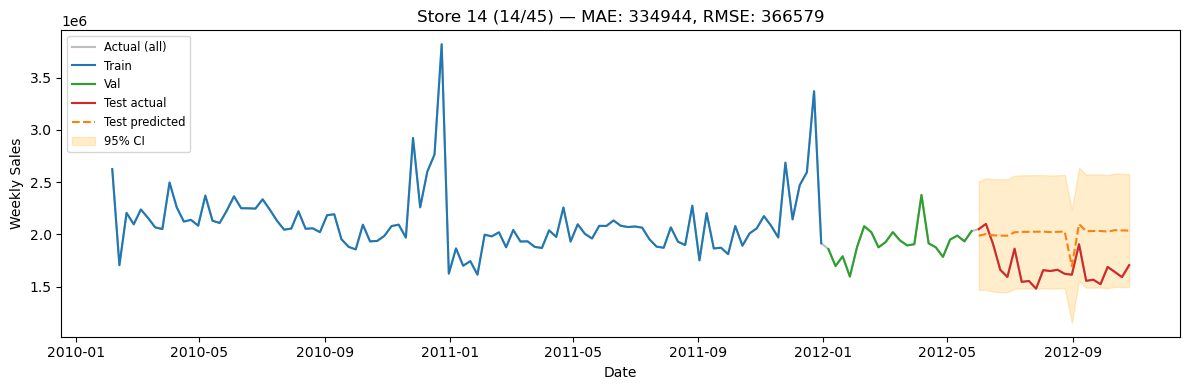

Processing store 15/45 (Store ID: 15)...
  Store 15 -> MAE: 55753.40, RMSE: 64518.01


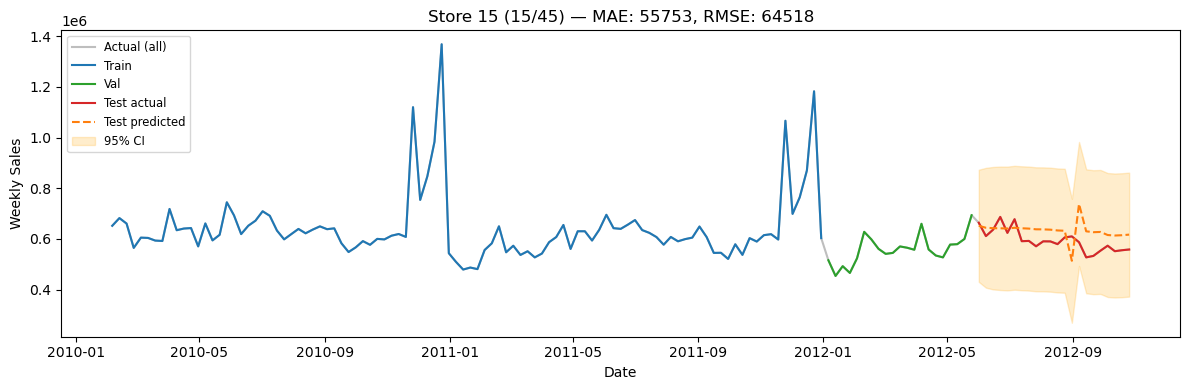

Processing store 16/45 (Store ID: 16)...
  Store 16 -> MAE: 36860.72, RMSE: 44881.67


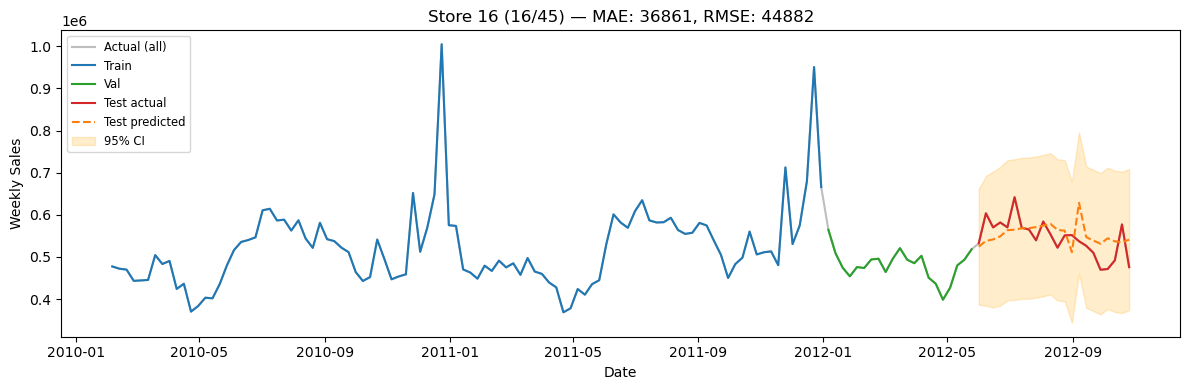

Processing store 17/45 (Store ID: 17)...
  Store 17 -> MAE: 48992.10, RMSE: 70101.90


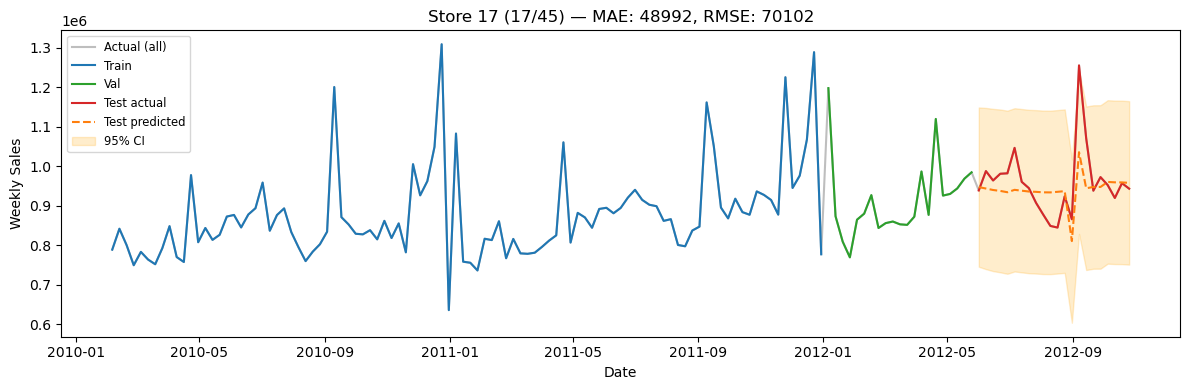

Processing store 18/45 (Store ID: 18)...
  Store 18 -> MAE: 59899.32, RMSE: 85038.77


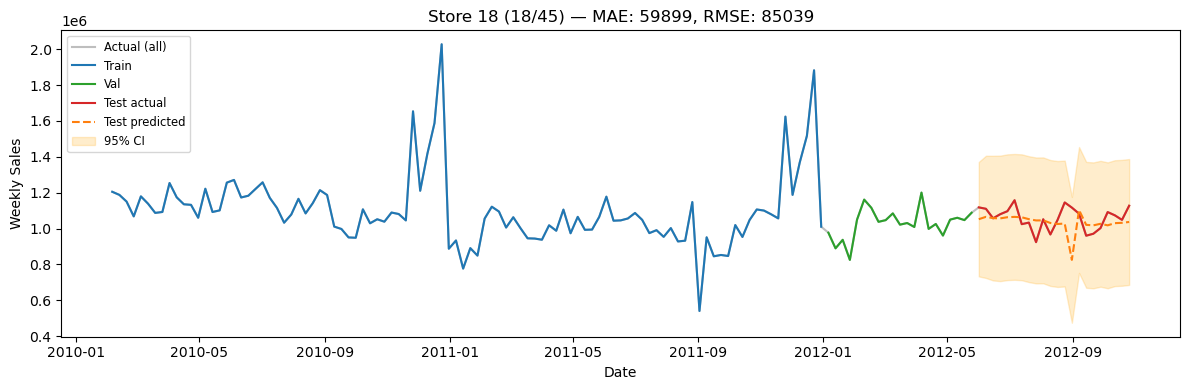

Processing store 19/45 (Store ID: 19)...
  Store 19 -> MAE: 96154.55, RMSE: 113235.26


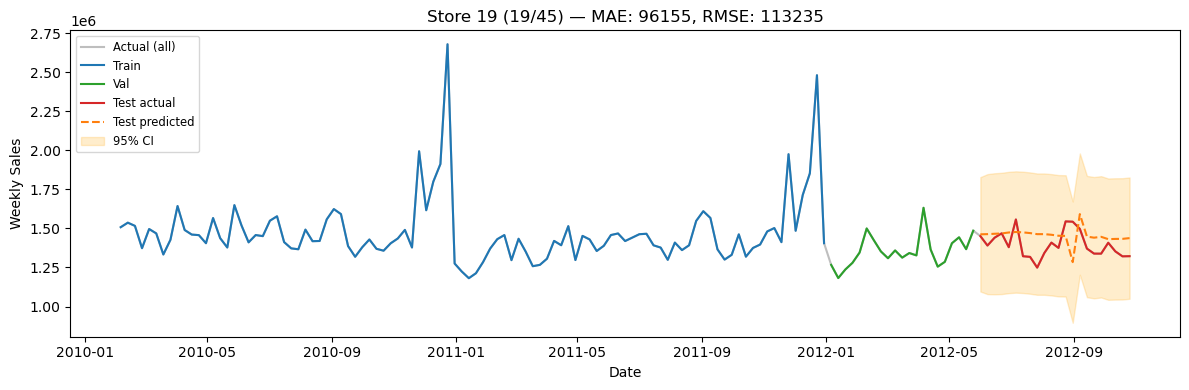

Processing store 20/45 (Store ID: 20)...
  Store 20 -> MAE: 98058.98, RMSE: 117595.08


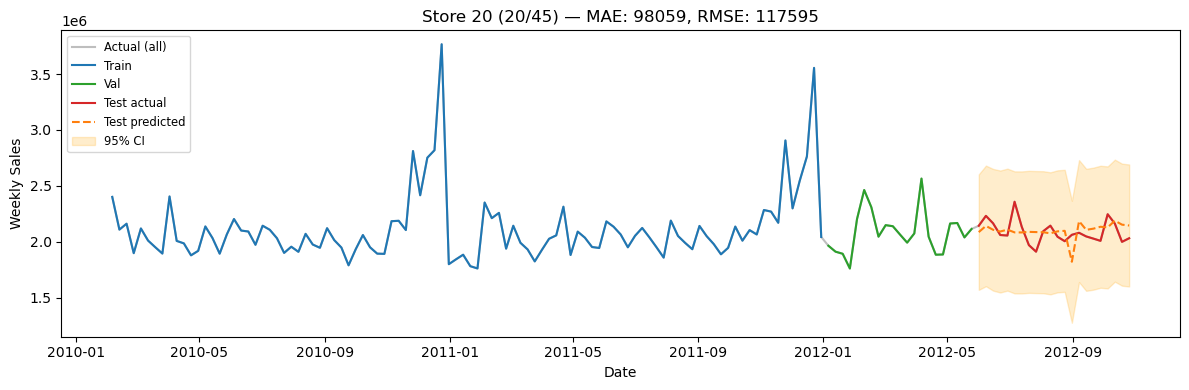

Processing store 21/45 (Store ID: 21)...
  Store 21 -> MAE: 46361.41, RMSE: 65898.67


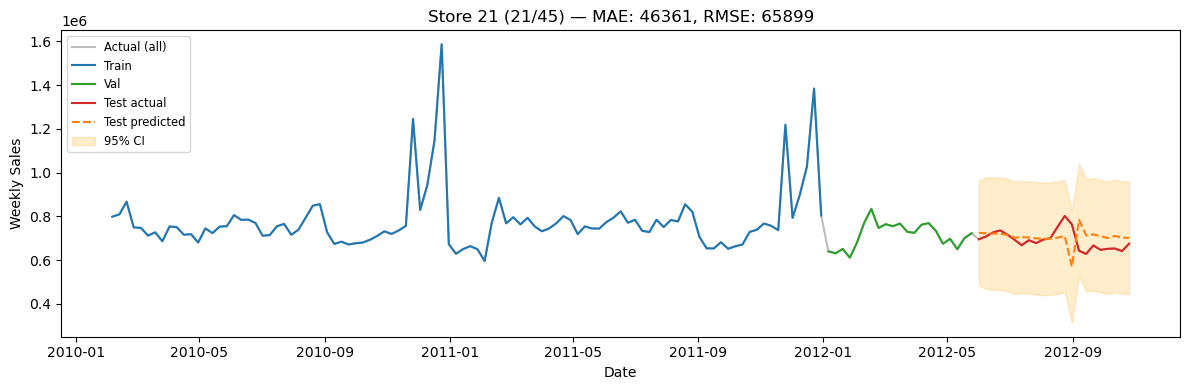

Processing store 22/45 (Store ID: 22)...
  Store 22 -> MAE: 57884.27, RMSE: 68627.02


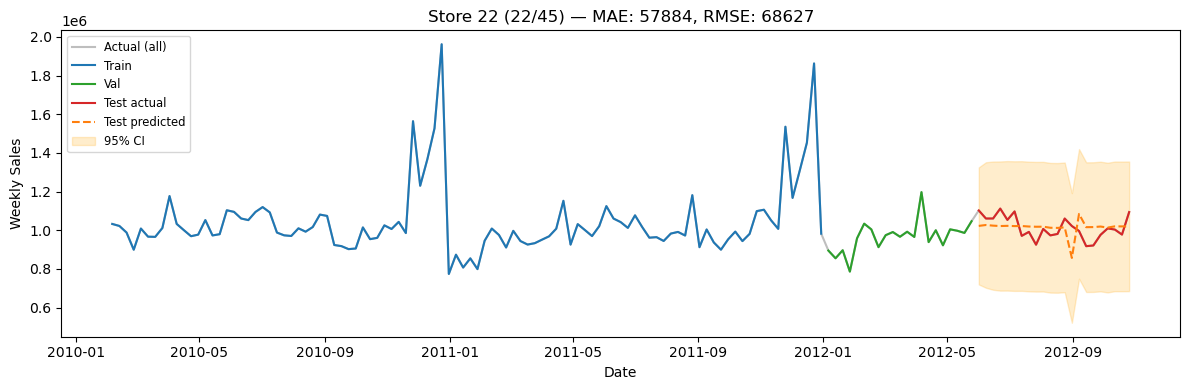

Processing store 23/45 (Store ID: 23)...
  Store 23 -> MAE: 86613.07, RMSE: 117730.98


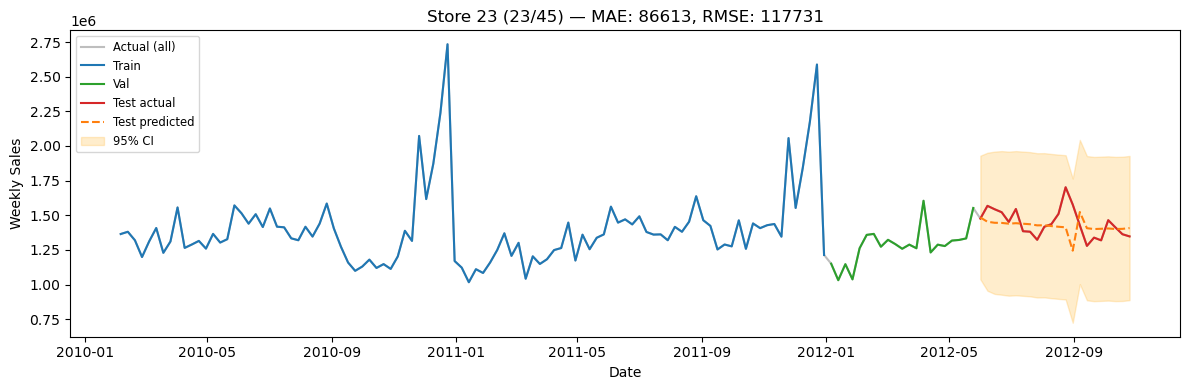

Processing store 24/45 (Store ID: 24)...
  Store 24 -> MAE: 80848.66, RMSE: 101266.94


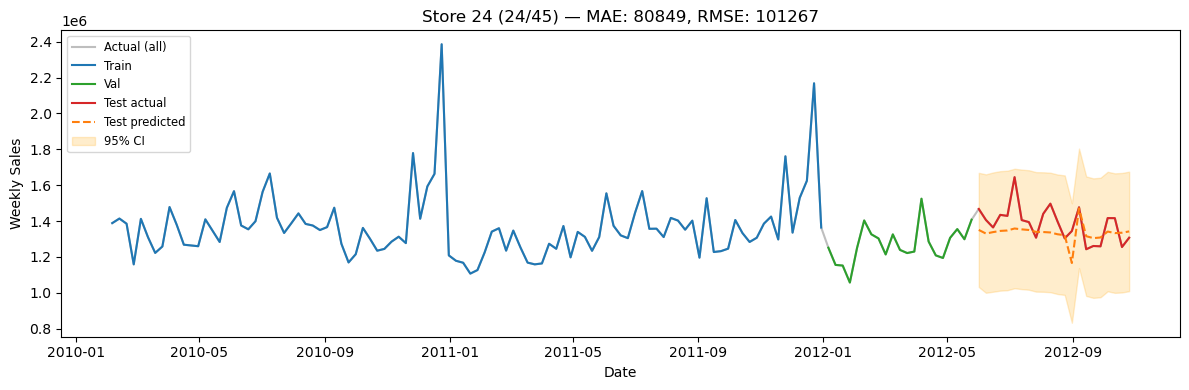

Processing store 25/45 (Store ID: 25)...
  Store 25 -> MAE: 30649.47, RMSE: 36930.97


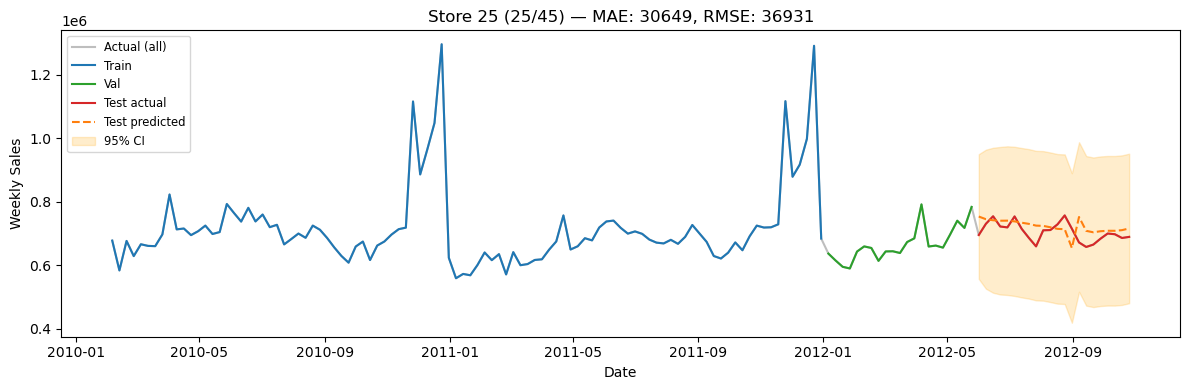

Processing store 26/45 (Store ID: 26)...
  Store 26 -> MAE: 44838.49, RMSE: 57626.44


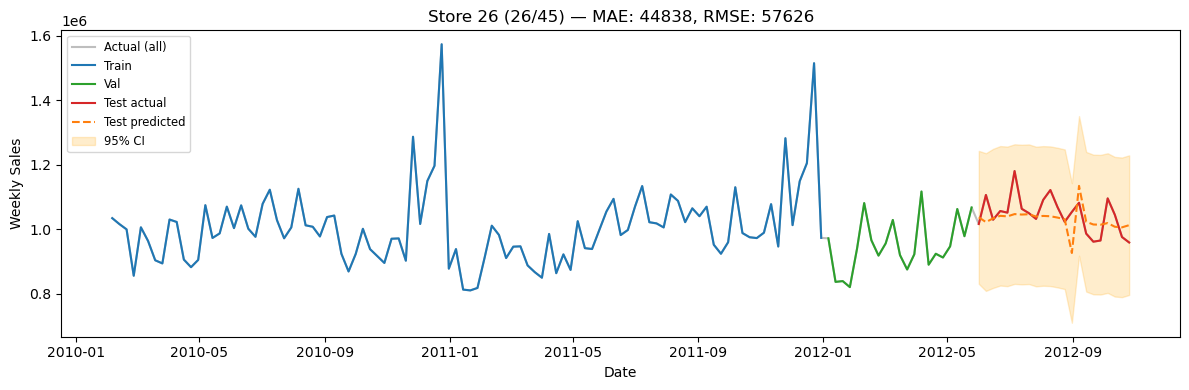

Processing store 27/45 (Store ID: 27)...
  Store 27 -> MAE: 126233.43, RMSE: 144723.44


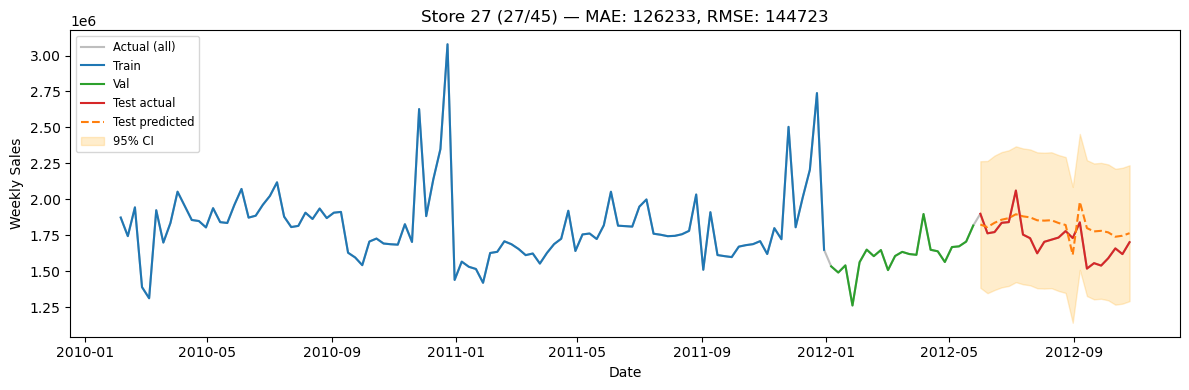

Processing store 28/45 (Store ID: 28)...
  Store 28 -> MAE: 102036.93, RMSE: 131622.10


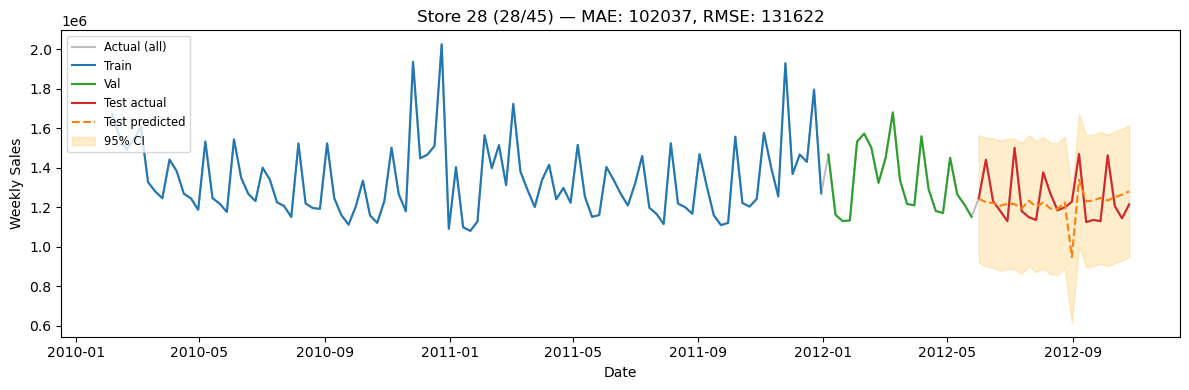

Processing store 29/45 (Store ID: 29)...
  Store 29 -> MAE: 40234.76, RMSE: 52426.54


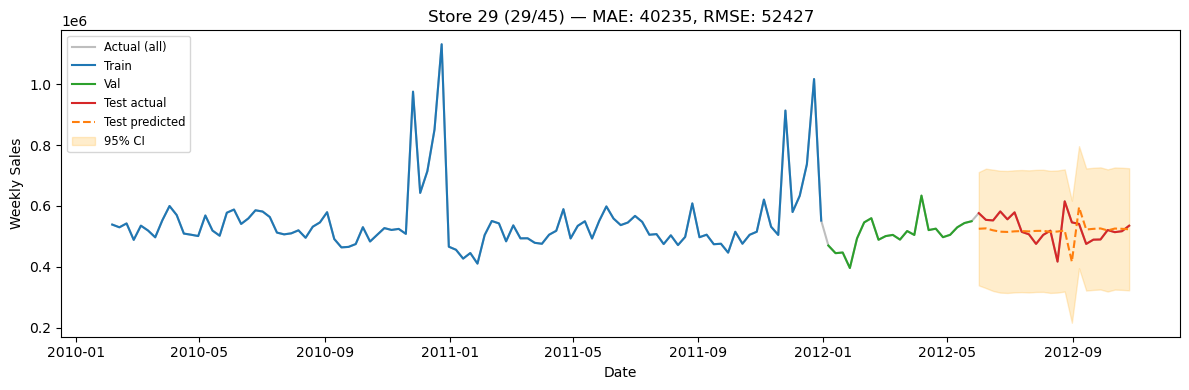

Processing store 30/45 (Store ID: 30)...
  Store 30 -> MAE: 11603.80, RMSE: 14688.28


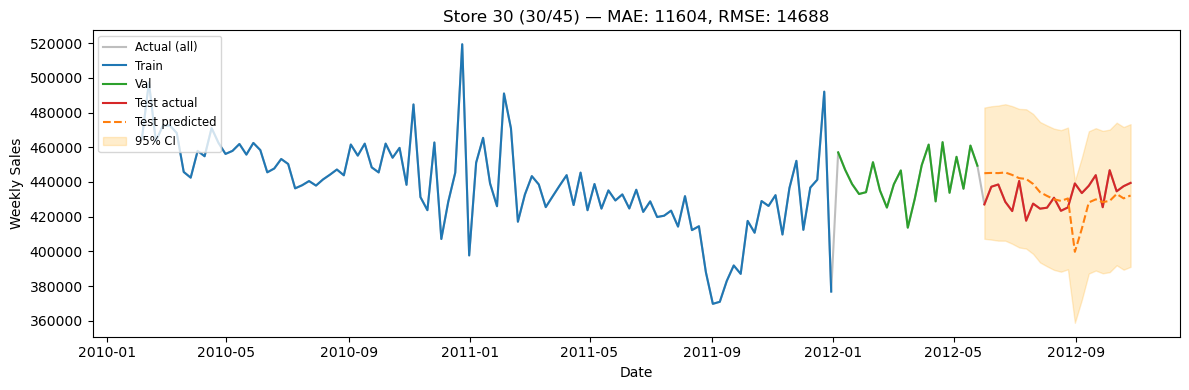

Processing store 31/45 (Store ID: 31)...
  Store 31 -> MAE: 51729.24, RMSE: 68247.44


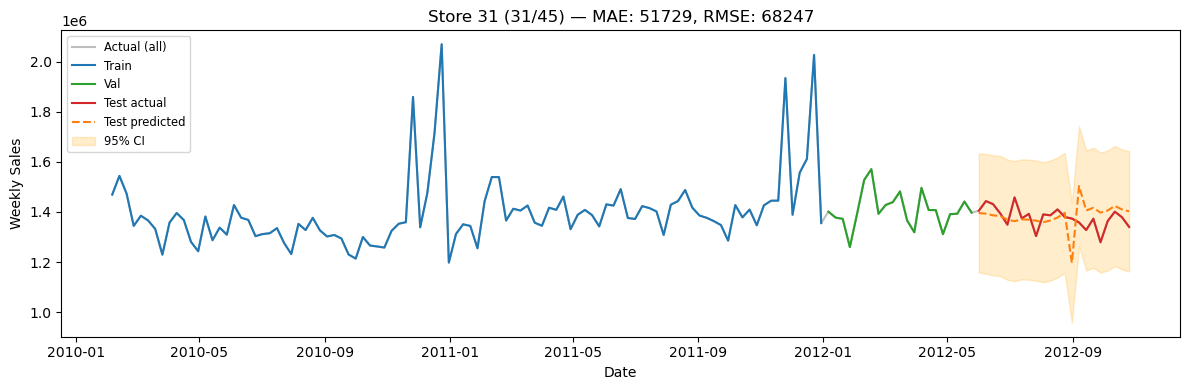

Processing store 32/45 (Store ID: 32)...
  Store 32 -> MAE: 64893.42, RMSE: 82675.51


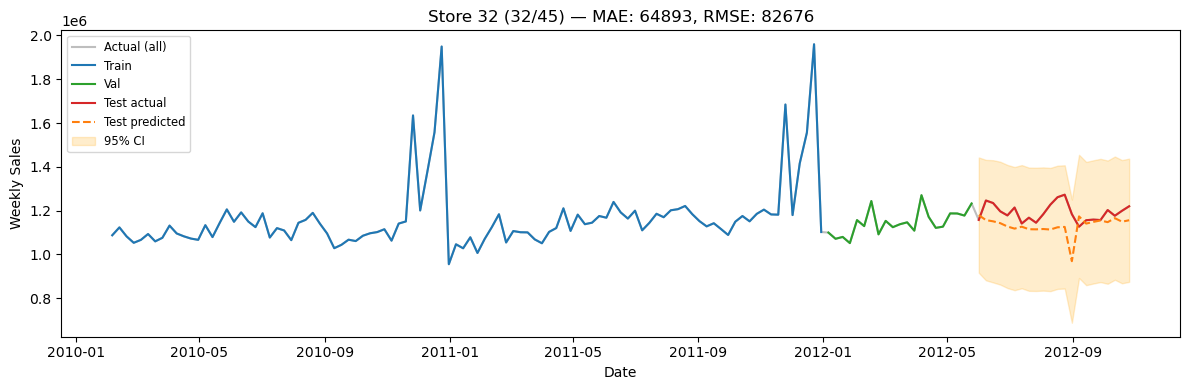

Processing store 33/45 (Store ID: 33)...
  Store 33 -> MAE: 22695.29, RMSE: 28177.58


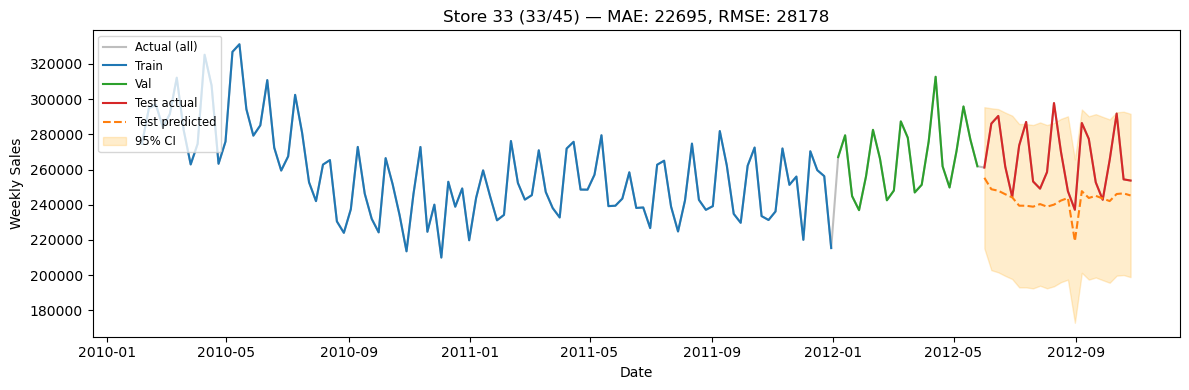

Processing store 34/45 (Store ID: 34)...
  Store 34 -> MAE: 34874.60, RMSE: 48418.41


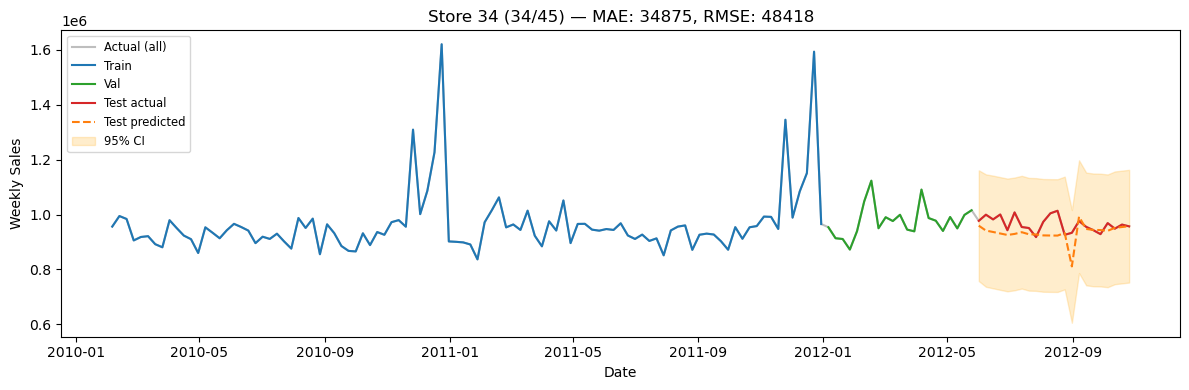

Processing store 35/45 (Store ID: 35)...
  Store 35 -> MAE: 62783.75, RMSE: 86926.89


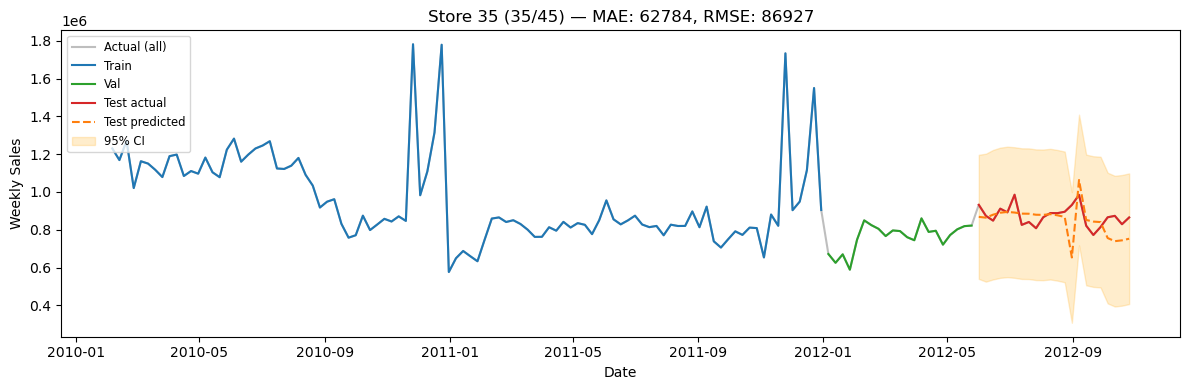

Processing store 36/45 (Store ID: 36)...
  Store 36 -> MAE: 15912.55, RMSE: 19211.34


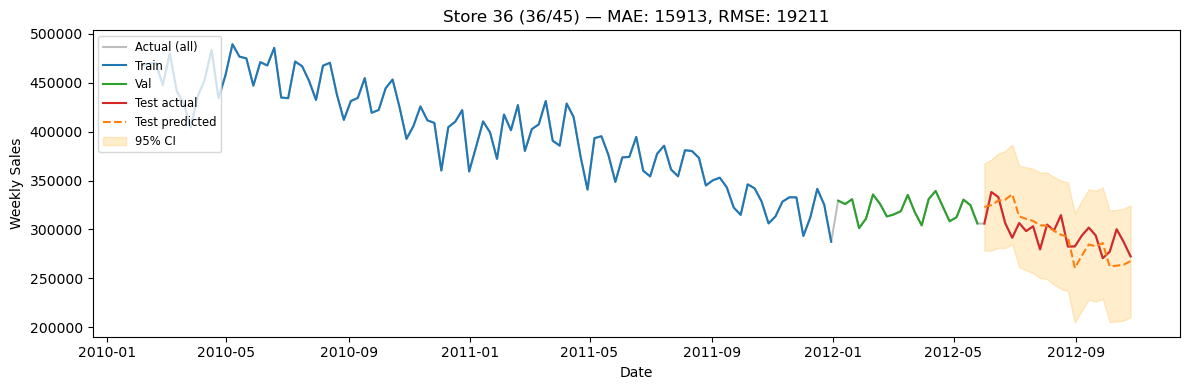

Processing store 37/45 (Store ID: 37)...
  Store 37 -> MAE: 13094.58, RMSE: 16447.98


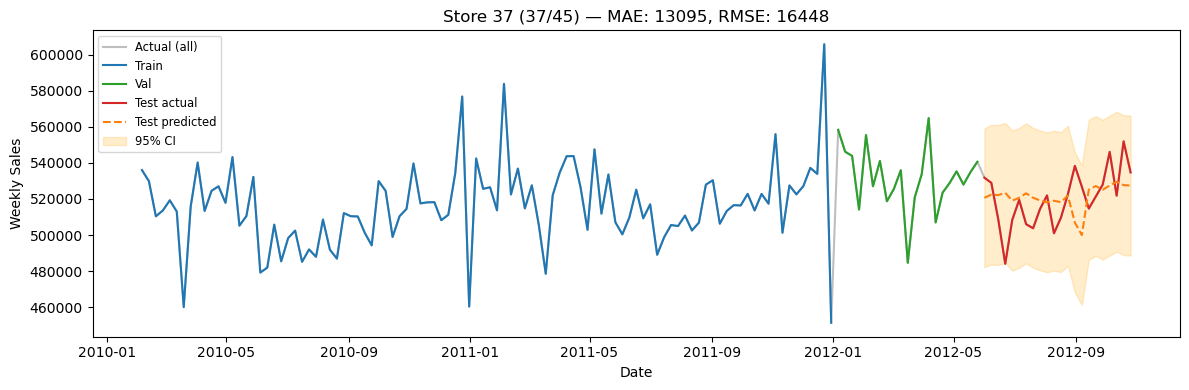

Processing store 38/45 (Store ID: 38)...
  Store 38 -> MAE: 33511.35, RMSE: 38502.47


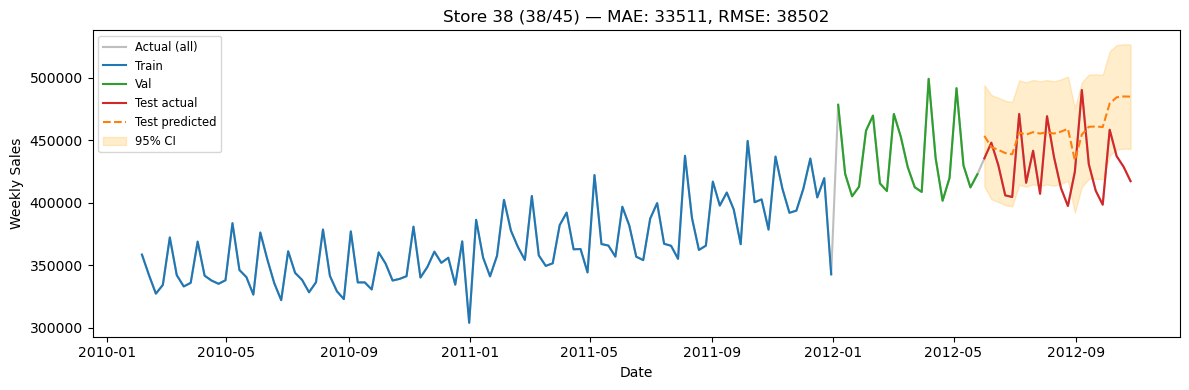

Processing store 39/45 (Store ID: 39)...
  Store 39 -> MAE: 91690.36, RMSE: 109085.34


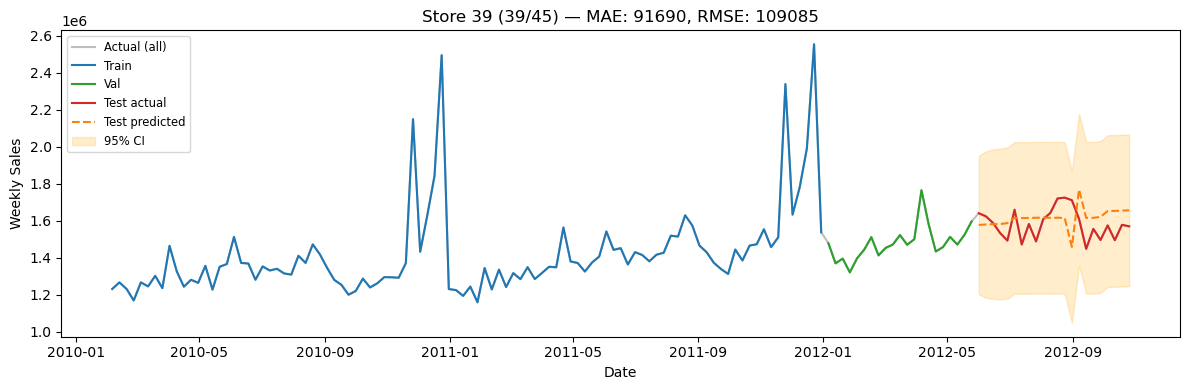

Processing store 40/45 (Store ID: 40)...
  Store 40 -> MAE: 55911.93, RMSE: 68734.80


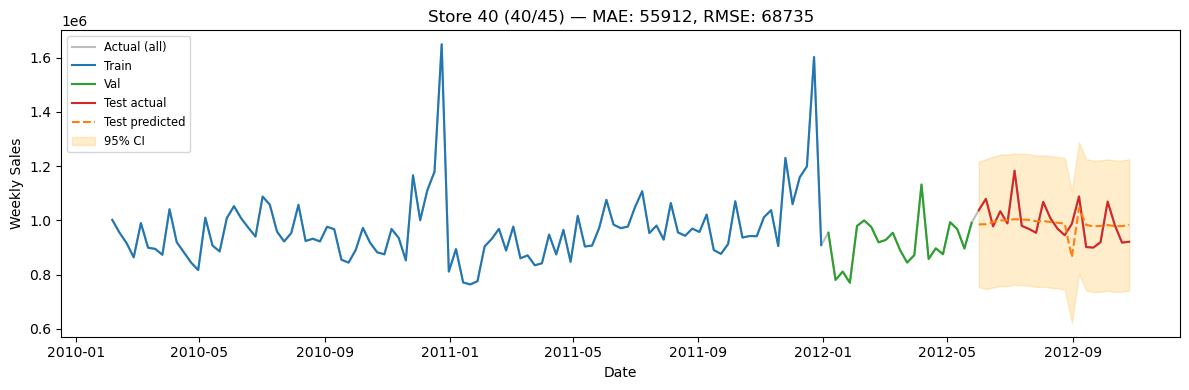

Processing store 41/45 (Store ID: 41)...
  Store 41 -> MAE: 69652.86, RMSE: 92942.22


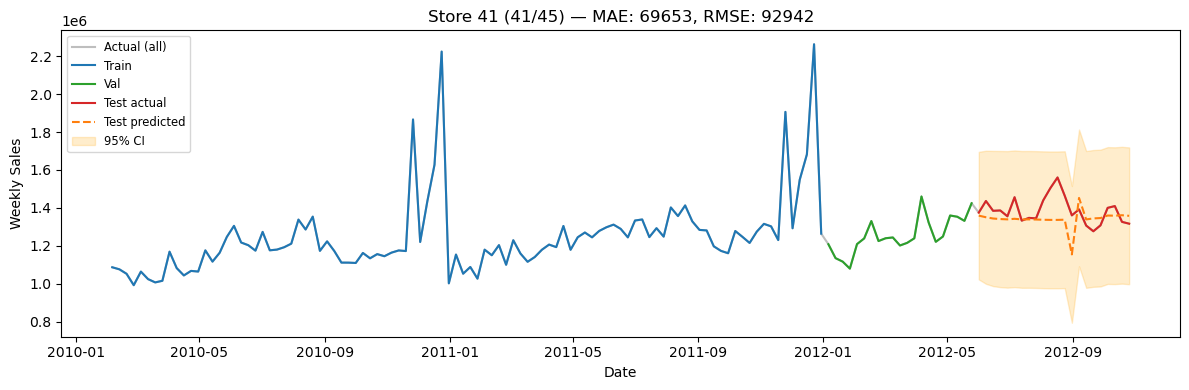

Processing store 42/45 (Store ID: 42)...
  Store 42 -> MAE: 38468.34, RMSE: 46806.29


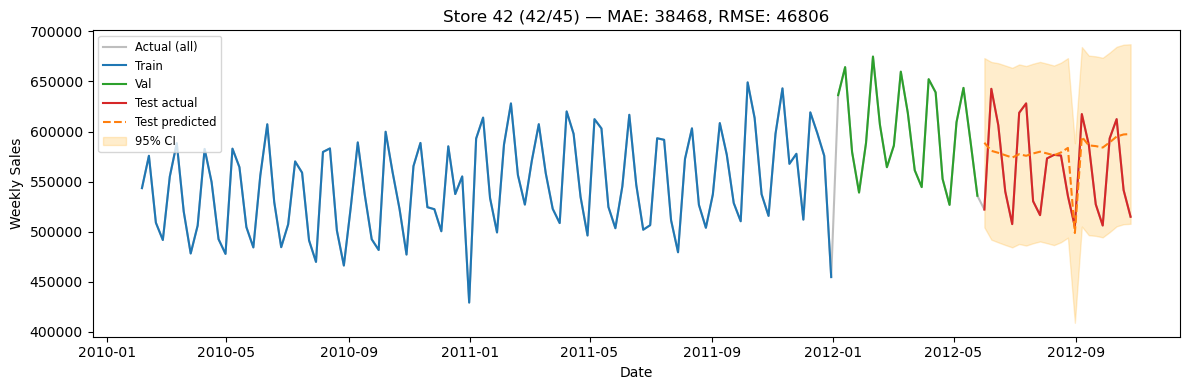

Processing store 43/45 (Store ID: 43)...
  Store 43 -> MAE: 59250.70, RMSE: 64778.87


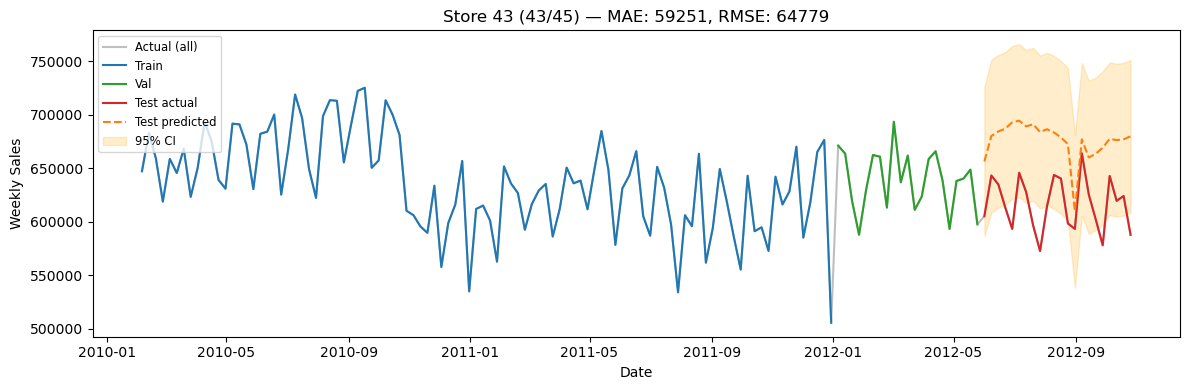

Processing store 44/45 (Store ID: 44)...
  Store 44 -> MAE: 15162.15, RMSE: 17898.50


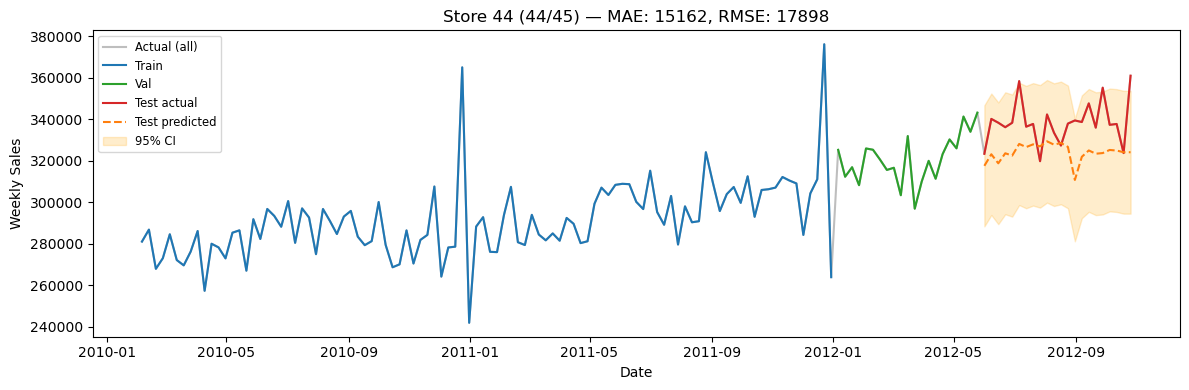

Processing store 45/45 (Store ID: 45)...
  Store 45 -> MAE: 54298.78, RMSE: 59375.75


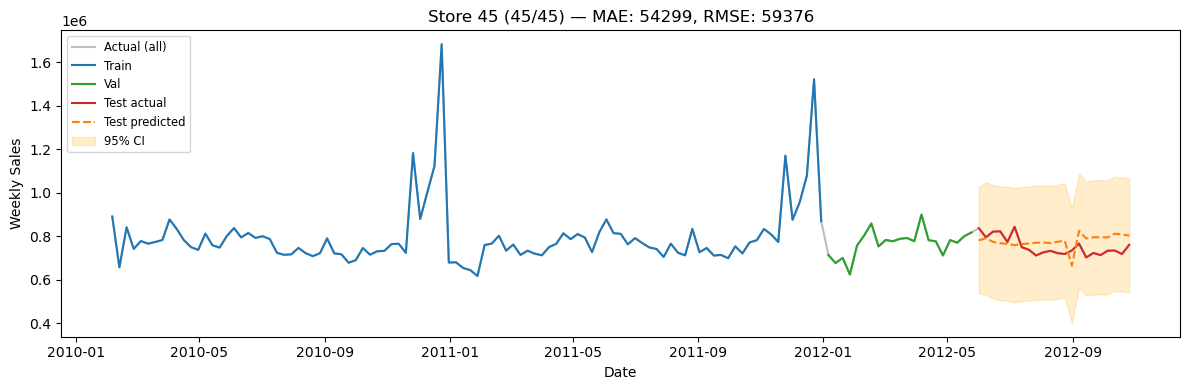


Summary:
  Processed stores: 45, Skipped: 0
  Average MAE across stores: 65177.12
  Average RMSE across stores: 79962.31


In [20]:
# ...existing code...
# Cell X - Run SARIMAX per store using LSTM features as exogenous, print progress and plot (no saving)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# create LSTM-like features (major/minor holidays + monthly cyclic)
def thanksgiving_date(year):
    d = pd.Timestamp(year=year, month=11, day=1)
    first_thursday = 1 + ((3 - d.weekday()) % 7)
    return pd.Timestamp(year=year, month=11, day=first_thursday + 21).date()

years = df['Date'].dt.year.unique()
thanksgiving_dates = {int(y): thanksgiving_date(int(y)) for y in years}

def is_major(d):
    if (d.month == 12 and d.day == 25):
        return 1
    ty = int(d.year)
    if thanksgiving_dates.get(ty) == d.date():
        return 1
    return 0

df = df.copy()
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)
df['is_major_holiday'] = df['Date'].apply(lambda x: is_major(x) if pd.notnull(x) else 0)
if 'Holiday_Flag' in df.columns:
    df['is_minor_holiday'] = ((df['Holiday_Flag'] == 1) & (df['is_major_holiday'] == 0)).astype(int)
else:
    df['is_minor_holiday'] = 0
df['Month'] = df['Date'].dt.is_month_end

# features to use as exogenous (same as LSTM)
exog_cols = ['is_major_holiday', 'is_minor_holiday', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Month']

stores = sorted(df['Store'].unique())
mae_list = []
rmse_list = []
processed = 0
skipped = 0

# fall back ARIMA order if not set earlier
try:
    _ = (p, d, q)
except Exception:
    p, d, q = 1, 0, 1

total = len(stores)
for idx, store_id in enumerate(stores):
    print(f"Processing store {idx+1}/{total} (Store ID: {store_id})...")
    store_data = df[df['Store'] == store_id].copy().sort_values('Date')
    if store_data.empty:
        print(f"  Skipping store {store_id}: no rows")
        skipped += 1
        continue

    # ensure Date and Weekly_Sales numeric, drop bad rows
    store_data['Date'] = pd.to_datetime(store_data['Date'], errors='coerce')
    store_data = store_data.dropna(subset=['Date']).sort_values('Date')
    store_data['Weekly_Sales'] = pd.to_numeric(store_data['Weekly_Sales'], errors='coerce')
    # prepare exogenous vars; fill small gaps with ffill/bfill to avoid NaN errors
    for c in exog_cols:
        if c not in store_data.columns:
            store_data[c] = 0
    store_data[exog_cols] = store_data[exog_cols].astype(float)
    store_data[exog_cols] = store_data[exog_cols].fillna(method='ffill').fillna(method='bfill').fillna(0)

    store_data = store_data.dropna(subset=['Weekly_Sales'])
    n = len(store_data)
    if n < 10:
        print(f"  Skipping store {store_id}: not enough valid Weekly_Sales rows ({n})")
        skipped += 1
        continue

    try:
        train_end = int(0.7 * n)
        val_end = int(0.85 * n)
        if train_end < 3 or (n - val_end) < 1:
            print(f"  Skipping store {store_id}: insufficient split sizes (n={n}, train={train_end}, test={n-val_end})")
            skipped += 1
            continue

        series = store_data.set_index('Date')['Weekly_Sales'].sort_index()
        exog = store_data.set_index('Date')[exog_cols].sort_index()

        train = series.iloc[:train_end]
        val = series.iloc[train_end:val_end]
        test = series.iloc[val_end:]

        train_exog = exog.iloc[:train_end]
        val_exog = exog.iloc[train_end:val_end]
        test_exog = exog.iloc[val_end:]

        # Skip constant/near-constant train
        if train.std() == 0 or train.nunique() == 1:
            print(f"  Skipping store {store_id}: train series constant")
            skipped += 1
            continue

        # Fit SARIMAX on training portion with exogenous
        sarimax_mod = SARIMAX(train, exog=train_exog, order=(p, d, q))
        sarimax_res = sarimax_mod.fit(disp=False)

        # Refit on train+val
        train_val = pd.concat([train, val]) if len(val) > 0 else train
        train_val_exog = pd.concat([train_exog, val_exog]) if len(val_exog) > 0 else train_exog
        sarimax_tv = SARIMAX(train_val, exog=train_val_exog, order=(p, d, q)).fit(disp=False)

        if len(test) > 0:
            # forecast with exog for test horizon
            fc = sarimax_tv.get_forecast(steps=len(test), exog=test_exog)
            test_pred = pd.Series(fc.predicted_mean, index=test.index)
            try:
                conf = fc.conf_int()
                conf.index = test.index
                lower = conf.iloc[:,0]
                upper = conf.iloc[:,1]
            except Exception:
                lower = None
                upper = None

            mae_val = mean_absolute_error(test, test_pred)
            rmse_val = mean_squared_error(test, test_pred, squared=False)
            mae_list.append(mae_val)
            rmse_list.append(rmse_val)
            processed += 1
            print(f"  Store {store_id} -> MAE: {mae_val:.2f}, RMSE: {rmse_val:.2f}")

            # Plot actual vs pred with CI
            plt.figure(figsize=(12,4))
            plt.plot(series.index, series.values, label='Actual (all)', color='tab:gray', alpha=0.5)
            plt.plot(train.index, train.values, label='Train', color='tab:blue')
            if len(val) > 0:
                plt.plot(val.index, val.values, label='Val', color='tab:green')
            plt.plot(test.index, test.values, label='Test actual', color='tab:red')
            plt.plot(test_pred.index, test_pred.values, label='Test predicted', color='tab:orange', linestyle='--')
            if lower is not None and upper is not None:
                plt.fill_between(test.index, lower.values, upper.values, color='orange', alpha=0.2, label='95% CI')
            plt.title(f"Store {store_id} ({idx+1}/{total}) — MAE: {mae_val:.0f}, RMSE: {rmse_val:.0f}")
            plt.xlabel('Date')
            plt.ylabel('Weekly Sales')
            plt.legend(loc='upper left', fontsize='small')
            plt.tight_layout()
            plt.show()
        else:
            print(f"  No test set for store {store_id}, skipping metric computation.")
            skipped += 1

    except Exception as e:
        print(f"  Error processing store {store_id}: {e}")
        skipped += 1
        continue

# final summary
if processed > 0:
    avg_mae = np.mean(mae_list)
    avg_rmse = np.mean(rmse_list)
    print('\nSummary:')
    print(f"  Processed stores: {processed}, Skipped: {skipped}")
    print(f"  Average MAE across stores: {avg_mae:.2f}")
    print(f"  Average RMSE across stores: {avg_rmse:.2f}")
else:
    print('No stores were processed successfully. Check data and exogenous variables.')
# ...existing code...

NameError: name 'pd' is not defined